# English Syntax Explorer – T5-large + spaCy + luật (v4, A100)

**Mục tiêu bản v4:** tăng **Exact Match**, **Precision** và **F1** so với v3 (v3 trên tập test cũ: EM 65.0 · P 95.6 · R 93.6 · F1 94.6).

Vẫn giữ thiết kế **so sánh 4 mô hình (2×2)** trên cùng tập test:

| | **Có luật** | **Không luật** |
|---|---|---|
| **Có spaCy** | ① **Đầy đủ** | ③ Bỏ luật |
| **Không spaCy** | ② Bỏ spaCy | ④ **Gốc** (T5 thuần, chỉ fine-tune) |

**Những gì thay đổi so với v3**

1. **Dữ liệu cleaned** (`420_câu_mẫu_NCKH_cleaned.xlsx`): cả 430/430 dòng dùng được (v3 chỉ 397). **Sửa bug:** ký hiệu chỉ số dưới `NP₁`, `.₁` bị tokenizer T5 đổi thành `NP1`, `.1`, nên các câu có chỉ số **không bao giờ khớp Exact**. Giờ cây chuẩn được chuẩn hoá ngay lúc nạp.
2. **Giải mã có ràng buộc** (constrained decoding): mỗi bước beam search chỉ cho sinh token tạo ra cây **cân ngoặc**, **nhãn có trong kho nhãn học từ train**, và **lá đúng là các từ của câu theo thứ tự**. Vì vậy mọi ứng viên n-best đều là cây hợp lệ, không còn nhãn “bịa” (`noun`, `PROG never`…).
3. **Luật sửa lỗi học từ dữ liệu**, mỗi luật được **kiểm định chéo 5-fold trên cây chuẩn train** (luật nào làm hỏng > 2% cây đúng thì bị tắt), sau đó chọn tổ hợp luật trên validation:
   - *thì*: `[past]/[pres]` theo tag spaCy của chính từ đó (VBD → past, VBZ/VBP → pres);
   - *tiểu loại động từ theo khung VP*: `V[trans] + NP + NP` → `V[ditrans]`…;
   - *nhãn từ đóng*: `every` → `Q`… và *tag spaCy → nhãn* (vd. `NNP` → `name`), chỉ đổi khi quy tắc sinh mới đã từng gặp ở train.
4. **Xếp hạng lại n-best** = bỏ phiếu xác suất − phạt grammar prior − phạt nhãn từ loại lạ (từ điển + tag spaCy) + **MBR** (đồng thuận F1 giữa các ứng viên). Nếu mô hình không tự tin (log-xác suất < ngưỡng τ) thì dùng cây template. Trọng số và τ chọn trên validation.
5. **Huấn luyện**: chọn checkpoint theo *EM + F1* của giải mã có ràng buộc (ổn định hơn greedy tự do), sau đó **huấn luyện lại trên train + val** với số epoch tốt nhất (`CFG["final_train_on_trainval"]`). Tập test vẫn chỉ dùng ở mục 10.

Ngoài bảng 2×2 có thêm: **⑤ Kết hợp A+B** (gộp n-best của cả 2 mô hình rồi qua luật v4 – thường cho EM/F1 cao nhất), và 2 dòng tham chiếu: **① với tầng luật v3 cũ** (cùng mô hình, để thấy riêng phần luật v4 tăng bao nhiêu) và **T5-large chưa fine-tune**. Ứng dụng Gradio dùng hệ thống tốt hơn trên validation giữa ① và ⑤.

**Cách chạy:** Runtime → Change runtime type → **A100 GPU** → Run all. Cài đặt xong nên *Restart runtime* một lần rồi chạy tiếp từ cell cấu hình. Thời gian: khoảng 60–80 phút trên A100 (2 mô hình × 2 pha). Checkpoint lưu trong `syntax_model_v4/` và tự nạp lại khi chạy lại (`CFG["retrain"]=True` để huấn luyện lại).

## 1. Cài đặt thư viện

In [1]:
!pip -q install transformers sentencepiece accelerate spacy pyspellchecker graphviz gradio openpyxl
!python -m spacy download en_core_web_sm
!apt-get -qq install -y graphviz > /dev/null

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 49.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## 2. Cấu hình & kiểm tra GPU

In [2]:
import os, re, json, math, random, time, unicodedata, itertools, copy, glob
import numpy as np
import pandas as pd
import torch

CFG = dict(
    data_path="420_câu_mẫu_NCKH_cleaned.xlsx",  # không thấy thì tìm *NCKH*.xlsx trong thư mục hiện tại, rồi mới hỏi upload
    sheet="dataset",
    model_name="google/flan-t5-large",
    spacy_model="en_core_web_sm",
    out_dir="syntax_model_v4",           # thư mục MỚI để không nạp nhầm checkpoint v3 (đổi sang /content/drive/MyDrive/... nếu muốn giữ)
    auto_repair=True,
    augment_factor=1,
    # ---- huấn luyện (tối ưu cho A100 40/80GB, bf16) ----
    epochs=40,
    batch_size=8,
    grad_accum_steps=2,                  # batch hiệu dụng = 16
    optimizer="adamw",                   # "adamw" hoặc "adafactor"
    lr=1e-4,                             # AdamW: 1e-4 | Adafactor: dùng 5e-4 ~ 1e-3
    weight_decay=0.01,
    warmup_ratio=0.06,
    patience=10,
    max_src_len=256,
    final_train_on_trainval=True,        # pha 2: huấn luyện lại trên train+val với số epoch tốt nhất của pha 1
    # ---- giải mã ----
    num_beams=8,
    n_best=8,                            # số ứng viên giữ lại để lọc luật / bỏ phiếu
    constrained=True,                    # giải mã có ràng buộc: cây cân ngoặc, nhãn hợp lệ, lá = đúng các từ của câu
    rule_audit_min=0.98,                 # luật sửa lỗi phải giữ nguyên ≥ 98% cây chuẩn (kiểm định chéo 5-fold trên train)
    # ---- điều khiển ----
    retrain=False,                       # True: huấn luyện lại dù đã có checkpoint
    include_zero_shot=True,              # thêm 1 dòng tham chiếu: T5-large chưa fine-tune
    include_legacy_rules=True,           # thêm 1 dòng tham chiếu: mô hình đầy đủ nhưng dùng tầng luật v3
    seed=42,
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(CFG["seed"])
os.makedirs(CFG["out_dir"], exist_ok=True)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
if device == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
USE_BF16 = device == "cuda" and torch.cuda.is_bf16_supported()

print("torch", torch.__version__, "| CUDA", torch.version.cuda)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "KHÔNG có GPU CUDA – hãy bật GPU (A100) trong Runtime")
print("bf16:", USE_BF16)
if device == "cuda":
    try:
        a = torch.randn(512, 512, device="cuda")
        _ = float((a @ a).sum()); _ = float((a.to(torch.bfloat16) @ a.to(torch.bfloat16)).float().sum())
        torch.cuda.synchronize(); print("CUDA matmul OK")
    except Exception as e:
        raise RuntimeError("CUDA/cuBLAS lỗi. Hãy Runtime -> Disconnect and delete runtime, cấp lại máy rồi chạy lại từ đầu.") from e

torch 2.11.0+cu130 | CUDA 13.0
Device: cuda | NVIDIA A100-SXM4-80GB
bf16: True
CUDA matmul OK


## 3. Thư viện xử lý cây cú pháp (`treelib.py`)
Giữ như v3 (nhãn, linearize/delinearize, chỉ số span, chức năng ngữ pháp, vẽ cây). Thêm `normalize_subscripts` để chuẩn hoá `₁ → 1` ngay từ dữ liệu gốc.

In [3]:
%%writefile treelib.py
import re, random
from collections import Counter, defaultdict

TOK_RE = re.compile(r"\(|\)|[^\s()]+")

SUBSCRIPTS = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")

def normalize_subscripts(text):
    """T5 tokenizer chuẩn hoá NFKC: NP₁ → NP1. Chuẩn hoá luôn cây gốc để so sánh nhất quán."""
    return str(text).translate(SUBSCRIPTS)

def parse_tree(s):
    toks = TOK_RE.findall(str(s))
    pos = 0
    def node():
        nonlocal pos
        if pos >= len(toks) or toks[pos] != "(":
            raise ValueError("expected '('")
        pos += 1
        if pos >= len(toks) or toks[pos] in "()":
            raise ValueError("missing label")
        label = toks[pos]; pos += 1
        while pos < len(toks) and toks[pos].startswith("["):
            label += toks[pos]; pos += 1
        kids = []
        while pos < len(toks) and toks[pos] != ")":
            if toks[pos] == "(":
                kids.append(node())
            else:
                kids.append(toks[pos]); pos += 1
        if pos >= len(toks):
            raise ValueError("unbalanced: missing ')'")
        pos += 1
        return (label, kids)
    t = node()
    if pos != len(toks):
        raise ValueError("unbalanced: extra tokens after root")
    return t

def is_word_leaf(n):
    return not n[1] and n[0][:1].islower()

def is_preterminal(n):
    return len(n[1]) == 1 and isinstance(n[1][0], str)

def to_str(n):
    lab, kids = n
    return "(" + lab + "".join(" " + (k if isinstance(k, str) else to_str(k)) for k in kids) + ")"

def leaves(n):
    out = []
    lab, kids = n
    if is_word_leaf(n):
        return [lab]
    for k in kids:
        out.extend([k] if isinstance(k, str) else leaves(k))
    return out

def norm_word(w):
    return re.sub(r"[^\w']", "", w.lower())

def sent_tokens(sentence):
    return [norm_word(w) for w in re.findall(r"[\w']+|[^\w\s]", sentence) if norm_word(w)]

def leaves_match(tree, sentence):
    return [norm_word(w) for w in leaves(tree)] == sent_tokens(sentence)

def normalize_tree_text(s):
    s = re.sub(r"\s+", " ", str(s)).strip()
    s = re.sub(r"\](?=[A-Za-z])", "] ", s)
    return s

LEXICAL = re.compile(r"^(V(\[.*)?|N|ART|POSS|P|A|Adv|DEG|C|name|pronoun)$")

def lexical_ok(n):
    lab, kids = n
    if LEXICAL.match(lab) and not (len(kids) == 1 and isinstance(kids[0], str)) and kids:
        return False
    return all(lexical_ok(k) for k in kids if not isinstance(k, str))

def shape_ok(n):
    lab, kids = n
    sub = [k for k in kids if not isinstance(k, str)]
    if lab == "DET" and any(k[0] == "NOM" for k in sub):
        return False
    if lab == "NP" and any(k[0] == "VP" for k in sub):
        return False
    return all(shape_ok(k) for k in sub)

def _valid(cand, sentence):
    try:
        t = parse_tree(cand)
    except ValueError:
        return None
    ok_shape = [k[0] for k in t[1] if not isinstance(k, str)] == ["NP", "VP"]
    return t if t[0] == "S" and ok_shape and lexical_ok(t) and shape_ok(t) and leaves_match(t, sentence) else None

def try_repair(s, sentence):
    s = normalize_tree_text(s)
    opens, closes = s.count("("), s.count(")")
    cands = []
    if opens > closes:
        d = opens - closes
        m = re.search(r"\)\s*\(VP\b", s)
        if m:
            i = m.start() + 1
            cands.append(("close-subject-NP", s[:i] + ")" + s[i:] + ")" * (d - 1)))
        cands.append(("append-at-end", s + ")" * d))
    elif closes > opens and closes - opens == 1:
        for m in re.finditer(r"\)\s*\(", s):
            cands.append(("drop-extra-)", s[:m.start()] + s[m.start() + 1:]))
    for how, c in cands:
        t = _valid(c, sentence)
        if t is not None:
            return t, how
    return None, None

def lab_enc(l):
    return l.replace("][", "_").replace("[", "_").replace("]", "")

def lab_dec(l):
    if "_" not in l:
        return l
    head, *feats = l.split("_")
    return head + "".join(f"[{f}]" for f in feats if f)

def linearize(n):
    lab, kids = n
    parts = ["(", lab_enc(lab)]
    for k in kids:
        parts.extend([k] if isinstance(k, str) else linearize(k))
    parts.append(")")
    return parts

def lin_str(n):
    return " ".join(linearize(n))

def delinearize(text):
    t = parse_tree(text)
    def dec(n):
        lab, kids = n
        return (lab_dec(lab) if not is_word_leaf((lab, kids)) else lab,
                [k if isinstance(k, str) else dec(k) for k in kids])
    return dec(t)

def spans_and_tags(n):
    spans, tags, idx = [], {}, [0]
    def rec(x):
        lab, kids = x
        if is_word_leaf(x):
            idx[0] += 1
            return
        if is_preterminal(x):
            tags[idx[0]] = lab; idx[0] += 1
            return
        s = idx[0]
        for k in kids:
            if not isinstance(k, str):
                rec(k)
        if idx[0] > s:
            spans.append((lab, s, idx[0]))
    rec(n)
    return Counter(spans), tags

def f1(gold, pred, labeled=True):
    g = Counter(gold if labeled else Counter((s, e) for _, s, e in gold.elements()))
    p = Counter(pred if labeled else Counter((s, e) for _, s, e in pred.elements()))
    tp = sum((g & p).values())
    if not sum(g.values()) and not sum(p.values()):
        return 1.0
    prec = tp / max(sum(p.values()), 1); rec = tp / max(sum(g.values()), 1)
    return 2 * prec * rec / (prec + rec) if prec + rec else 0.0

def evaluate(golds, preds):
    m = defaultdict(list)
    for gl, p in zip(golds, preds):
        if p is None:
            for k in ("exact", "lab_f1", "unlab_f1", "tag_acc"):
                m[k].append(0.0)
            m["valid"].append(0.0)
            continue
        m["valid"].append(1.0)
        ps, pt = spans_and_tags(p)
        best = None
        for g in gl:
            gs, gt = spans_and_tags(g)
            tag_acc = (sum(pt.get(i) == t for i, t in gt.items()) / max(len(gt), 1))
            sc = (float(to_str(g) == to_str(p)), f1(gs, ps), f1(gs, ps, False), tag_acc)
            if best is None or sc[1] > best[1]:
                best = sc
        for k, v in zip(("exact", "lab_f1", "unlab_f1", "tag_acc"), best):
            m[k].append(v)
    return {k: sum(v) / len(v) for k, v in m.items()}

SWAPPABLE = re.compile(r"^(N|name|pronoun|A|Adv|V\[[a-z]+\]\[past\])$")

def _frame(n):
    return tuple(k[0] for k in n[1] if not isinstance(k, str))

def _key(label, parent_frame):
    return (label, parent_frame) if label.startswith("V[") else (label, ())

def build_lexicon(trees):
    lex = defaultdict(set)
    def rec(n, pf):
        if is_preterminal(n) and SWAPPABLE.match(n[0]):
            lex[_key(n[0], pf)].add(n[1][0])
        for k in n[1]:
            if not isinstance(k, str):
                rec(k, _frame(n))
    for t in trees:
        rec(t, ())
    return {k: sorted(v) for k, v in lex.items() if len(v) > 1}

def augment_tree(tree, lex, rng, p=0.7):
    prev = [""]
    def rec(n, pf):
        lab, kids = n
        if is_word_leaf(n):
            prev[0] = lab.lower()
            return n
        if is_preterminal(n):
            w = kids[0]
            key = _key(lab, pf)
            if key in lex and prev[0] not in ("a", "an") and rng.random() < p:
                cand = [c for c in lex[key] if c != w and c[:1].isupper() == w[:1].isupper()]
                if cand:
                    w = rng.choice(cand)
            prev[0] = w.lower()
            return (lab, [w])
        fr = _frame(n)
        return (lab, [k if isinstance(k, str) else rec(k, fr) for k in kids])
    return rec(tree, ())

def detok(words, end="."):
    s = " ".join(words)
    s = s[:1].upper() + s[1:]
    return s + (end if end in ".?!" else ".")

def raw_tokens(sentence):
    return [w for w in re.findall(r"[\w']+|[^\w\s]", sentence) if norm_word(w)]

def snap_leaves(tree, sentence):
    toks = raw_tokens(sentence)
    it = iter(toks)
    def rec(n):
        lab, kids = n
        if is_word_leaf(n):
            next(it)
            return n
        out = []
        for k in kids:
            out.append(next(it) if isinstance(k, str) else rec(k))
        return (lab, out)
    return rec(tree)

VI_FUNC = {
    "subject": "Chủ ngữ", "predicate": "Vị ngữ", "object": "Tân ngữ",
    "io": "Tân ngữ gián tiếp", "do": "Tân ngữ trực tiếp",
    "subj_comp": "Bổ ngữ chủ ngữ", "obj_comp": "Bổ ngữ tân ngữ",
    "prep_comp": "Bổ ngữ giới từ", "adjunct": "Trạng ngữ/Phụ ngữ",
    "clause": "Mệnh đề",
}
FEATURE_VI = {
    "intrans": "nội động từ (intransitive)", "trans": "ngoại động từ (transitive)",
    "ditrans": "động từ hai tân ngữ (ditransitive)", "intens": "động từ nối (intensive/copular)",
    "complex": "ngoại động từ phức (complex-transitive)", "prep": "động từ + giới từ (prepositional)",
    "past": "quá khứ", "pres": "hiện tại",
}

def feats(label):
    return re.findall(r"\[([^\]]+)\]", label)

def _verb_of(vp):
    for k in vp[1]:
        if isinstance(k, str):
            continue
        if k[0] == "VP":
            r = _verb_of(k)
            if r:
                return r
        elif k[0].startswith("V[") or (k[0] == "V" and is_preterminal(k)):
            return k
    return None

def functions(tree):
    fn = {}
    def walk(n, path, parent, vtype):
        lab, kids = n
        sub = [(i, k) for i, k in enumerate(kids) if not isinstance(k, str)]
        if lab in ("S", "S'"):
            for i, k in sub:
                if k[0] == "NP" and lab == "S" and path == ():
                    fn[path + (i,)] = VI_FUNC["subject"]
                elif k[0] == "VP":
                    fn[path + (i,)] = VI_FUNC["predicate"]
                elif k[0] in ("S", "S'"):
                    fn[path + (i,)] = VI_FUNC["clause"]
        if lab == "VP":
            v = _verb_of(n)
            vt = (feats(v[0]) or [None])[0] if v else None
            nps = [(i, k) for i, k in sub if k[0] == "NP"]
            for j, (i, k) in enumerate(nps):
                if vt == "ditrans":
                    fn[path + (i,)] = VI_FUNC["io"] if j == 0 else VI_FUNC["do"]
                elif vt == "intens":
                    fn[path + (i,)] = VI_FUNC["subj_comp"]
                elif vt == "complex" and j == 1:
                    fn[path + (i,)] = VI_FUNC["obj_comp"]
                else:
                    fn[path + (i,)] = VI_FUNC["object"]
            for i, k in sub:
                if k[0] in ("AP", "AdvP", "PP"):
                    if vt == "intens" and k[0] == "AP":
                        fn[path + (i,)] = VI_FUNC["subj_comp"]
                    elif vt == "complex" and k[0] == "AP":
                        fn[path + (i,)] = VI_FUNC["obj_comp"]
                    elif vt == "prep" and k[0] == "PP":
                        fn[path + (i,)] = VI_FUNC["prep_comp"]
                    else:
                        fn[path + (i,)] = VI_FUNC["adjunct"]
        for i, k in sub:
            walk(k, path + (i,), lab, None)
    walk(tree, (), None, None)
    return fn

def grammar_info(tree):
    fn = functions(tree)
    info = {"Chủ ngữ": [], "Vị ngữ": [], "Động từ": [], "Tân ngữ": [], "Bổ ngữ": [],
            "Trạng ngữ/Phụ ngữ": [], "Đặc điểm": []}
    def node_at(path):
        n = tree
        for i in path:
            n = n[1][i]
        return n
    for path, f in fn.items():
        txt = " ".join(leaves(node_at(path)))
        if f == VI_FUNC["subject"]:
            info["Chủ ngữ"].append(txt)
        elif f == VI_FUNC["predicate"]:
            info["Vị ngữ"].append(txt)
        elif f in (VI_FUNC["object"], VI_FUNC["io"], VI_FUNC["do"]):
            info["Tân ngữ"].append(f"{txt} ({f.lower()})")
        elif f in (VI_FUNC["subj_comp"], VI_FUNC["obj_comp"], VI_FUNC["prep_comp"]):
            info["Bổ ngữ"].append(f"{txt} ({f.lower()})")
        elif f == VI_FUNC["adjunct"]:
            info["Trạng ngữ/Phụ ngữ"].append(txt)

    def scan(n):
        lab, kids = n
        if is_preterminal(n) and (lab.startswith("V[") or lab.startswith("V ")):
            fs = feats(lab)
            desc = ", ".join(FEATURE_VI.get(x, x) for x in fs)
            info["Động từ"].append(f"{kids[0]}: {desc}")
        if lab.split("[")[0] in ("PASS", "PROG", "PERF", "MOD", "TENSE") and is_preterminal(n):
            names = {"PASS": "thể bị động", "PROG": "thể tiếp diễn", "PERF": "thể hoàn thành",
                     "MOD": "động từ khuyết thiếu", "TENSE": "thì"}
            info["Đặc điểm"].append(f"{kids[0]}: {names[lab.split('[')[0]]}")
        if is_word_leaf(n) and lab in ("not", "n't"):
            info["Đặc điểm"].append("câu phủ định (not)")
        for k in kids:
            if not isinstance(k, str):
                scan(k)
    scan(tree)
    return {k: v for k, v in info.items() if v}

COLORS = {"S": "#cfe2ff", "S'": "#cfe2ff", "NP": "#d4f4dd", "VP": "#ffd6d6", "PP": "#ffe8c2",
          "AP": "#e6d9ff", "AdvP": "#e6d9ff", "NOM": "#eaf7ee", "DET": "#f3f3f3"}

def tree_to_svg(tree):
    import graphviz
    g = graphviz.Digraph(format="svg")
    g.attr(rankdir="TB", nodesep="0.25", ranksep="0.45")
    g.attr("node", fontname="Helvetica", fontsize="12", shape="box", style="rounded,filled", margin="0.08,0.04")
    g.attr("edge", arrowhead="none", color="#6b7280")
    fn = functions(tree)
    cnt = [0]
    def rec(n, path):
        nid = f"n{cnt[0]}"; cnt[0] += 1
        lab, kids = n
        if is_word_leaf(n):
            g.node(nid, lab, fillcolor="white", color="#9ca3af", fontname="Helvetica-Oblique")
            return nid
        fs = feats(lab)
        base = lab.split("[")[0]
        text = base + ("\n" + "".join(f"[{x}]" for x in fs) if fs else "")
        if path in fn:
            text += f"\n({fn[path]})"
        fill = COLORS.get(base, "#fff7cc" if is_preterminal(n) else "#f3f4f6")
        g.node(nid, text, fillcolor=fill, color="#4b5563")
        for i, k in enumerate(kids):
            if isinstance(k, str):
                wid = f"w{cnt[0]}"; cnt[0] += 1
                g.node(wid, k, fillcolor="white", color="#9ca3af", fontname="Helvetica-Oblique")
                g.edge(nid, wid)
            else:
                g.edge(nid, rec(k, path + (i,)))
        return nid
    rec(tree, ())
    return g.pipe(format="svg").decode("utf-8")

Writing treelib.py


In [4]:
import sys; sys.path.insert(0, os.getcwd())
from treelib import *
print("treelib OK")

treelib OK


## 4. Đầu vào và tiền xử lý dữ liệu

In [5]:
if not os.path.exists(CFG["data_path"]):
    found = sorted(glob.glob("*NCKH*cleaned*.xlsx") + glob.glob("*NCKH*.xlsx"))
    if found:
        CFG["data_path"] = found[0]
    else:
        try:
            from google.colab import files
            up = files.upload()
            CFG["data_path"] = list(up.keys())[0]
        except ImportError:
            raise FileNotFoundError("Đặt file Excel vào CFG['data_path'] rồi chạy lại.")
print("Dữ liệu:", CFG["data_path"])

raw = pd.read_excel(CFG["data_path"], sheet_name=CFG["sheet"]).dropna(how="all").reset_index(drop=True)
raw["decision"] = raw["approved_tree"].notna()
raw.to_excel(os.path.join(CFG["out_dir"], "dataset_decision_true.xlsx"), index=False)
for c in ["sentence", "split", "category"]:
    raw[c] = raw[c].ffill()
raw["sentence"] = raw["sentence"].astype(str).str.strip()
print("Số dòng trong sheet:", len(raw))

records, report, seen = [], [], set()
for i, r in raw.iterrows():
    sent = r["sentence"]
    def log(status, how="", detail=""):
        report.append(dict(excel_row=i + 2, id=r.get("id"), sentence=sent, status=status, how=how, detail=detail))
    if pd.isna(r["approved_tree"]):
        log("skip_no_approved_tree"); continue
    text = normalize_tree_text(normalize_subscripts(r["approved_tree"]))      # NP₁ → NP1 (khớp với đầu ra tokenizer)
    how = "as-is"
    try:
        tree = parse_tree(text)
    except ValueError as err:
        tree, how = try_repair(text, sent) if CFG["auto_repair"] else (None, None)
        if tree is None:
            log("skip_unbalanced_brackets", detail=str(err)); continue
    if not leaves_match(tree, sent):
        log("skip_words_do_not_match_sentence", detail=" ".join(leaves(tree))); continue
    tree = snap_leaves(tree, sent)
    key = (sent.lower(), to_str(tree))
    if key in seen:
        log("skip_duplicate"); continue
    seen.add(key)
    log("ok" if how == "as-is" else "ok_repaired", how)
    records.append(dict(sentence=sent, split=r["split"], category=r["category"], tree=tree))

rep = pd.DataFrame(report)
rep.to_csv(os.path.join(CFG["out_dir"], "data_quality_report.csv"), index=False, encoding="utf-8-sig")
print(rep.status.value_counts().to_string())

SPLIT_MAP = {"development": "train", "validation": "val", "test": "test"}
for r_ in records:
    r_["split"] = SPLIT_MAP[r_["split"]]
df_rec = pd.DataFrame(records)
assert (df_rec.groupby(df_rec.sentence.str.lower()).split.nunique() <= 1).all(), "Có câu xuất hiện ở nhiều tập"
print("\nSố mẫu dùng được theo tập:", pd.Series([r_["split"] for r_ in records]).value_counts().to_dict())
print("Câu có nhiều cây chuẩn (mơ hồ):", int((df_rec.groupby("sentence").size() > 1).sum()))

Saving 420_câu_mẫu_NCKH_cleaned(1).xlsx to 420_câu_mẫu_NCKH_cleaned(1).xlsx
Dữ liệu: 420_câu_mẫu_NCKH_cleaned(1).xlsx
Số dòng trong sheet: 430
status
ok    430

Số mẫu dùng được theo tập: {'train': 301, 'test': 71, 'val': 58}
Câu có nhiều cây chuẩn (mơ hồ): 10


In [6]:
# Chẩn đoán: các luật cứng (lexical_ok / shape_ok) có thực sự đúng với MỌI cây chuẩn của tập train không?
# Nếu có cây chuẩn vi phạm thì luật đó bị tắt (tránh loại nhầm đáp án đúng – nguyên nhân hay gặp khiến "câu đơn giản không ra cây").
_train_trees = [r_["tree"] for r_ in records if r_["split"] == "train"]
RULE_FLAGS = dict(
    lexical=all(lexical_ok(t) for t in _train_trees),
    shape=all(shape_ok(t) for t in _train_trees),
)
for k_, ok_ in RULE_FLAGS.items():
    print(f"Luật '{k_}': {'BẬT' if ok_ else 'TẮT (có cây train vi phạm)'}")
_frames = Counter(tuple(k[0] for k in t[1] if not isinstance(k, str)) for t in _train_trees)
print("Khung gốc (S -> ...) trong train:", dict(_frames.most_common(8)))
_all_gold = [r_["tree"] for r_ in records]
print("Cây chuẩn (mọi tập) vi phạm lexical_ok:", sum(not lexical_ok(t) for t in _all_gold),
      "| shape_ok:", sum(not shape_ok(t) for t in _all_gold),
      "| gốc != S->NP VP:", sum(tuple(k[0] for k in t[1] if not isinstance(k, str)) != ("NP", "VP") for t in _all_gold))

Luật 'lexical': TẮT (có cây train vi phạm)
Luật 'shape': BẬT
Khung gốc (S -> ...) trong train: {('NP', 'VP'): 262, ("S'", 'S'): 11, ('C2', "S'"): 11, ('C', 'S'): 6, ('S', 'and', 'S'): 3, ('S', 'but', 'S'): 3, ('NP1', 'VP'): 2, ('PP', 'S'): 1}
Cây chuẩn (mọi tập) vi phạm lexical_ok: 26 | shape_ok: 0 | gốc != S->NP VP: 57


## 5. spaCy: gợi ý đầu vào + tăng cường dữ liệu
Tạo **hai dạng nguồn**: `src_spacy` (có gợi ý) cho mô hình A và `src_plain` (chỉ câu) cho mô hình B. Hàm `make_train_examples` dùng lại được cho pha 2 (train + val).

In [7]:
import spacy
nlp = spacy.load(CFG["spacy_model"])

def spacy_tokens(doc):
    """Các token spaCy tương ứng với lá của cây (bỏ dấu câu)."""
    return [t for t in doc if norm_word(t.text)]

def aligned_tokens(doc, sentence):
    """Trả về token spaCy nếu khớp 1-1 với token dùng làm lá của cây, ngược lại None."""
    st, raw_t = spacy_tokens(doc), raw_tokens(sentence)
    if len(st) == len(raw_t) and all(norm_word(a.text) == norm_word(b) for a, b in zip(st, raw_t)):
        return st
    return None

def leaf_tags(doc, sentence):
    """Tag spaCy cho TỪNG LÁ của cây, căn theo vị trí ký tự (chịu được cả khi spaCy tách từ khác, vd. didn't → did + n't)."""
    if doc is None:
        return None
    out = []
    for m in re.finditer(r"[\w']+|[^\w\s]", sentence):
        if not norm_word(m.group()):
            continue
        s, e = m.start(), m.end()
        toks = [t for t in doc if t.idx < e and t.idx + len(t.text) > s and norm_word(t.text)]
        out.append(toks[0].tag_ if toks else None)
    return out

def hint_string(doc):
    """Gợi ý spaCy theo từng từ:  <stt> <từ> <tag> <quan hệ phụ thuộc> <stt từ đầu>."""
    toks = spacy_tokens(doc)
    pos = {t.i: k for k, t in enumerate(toks, 1)}
    parts = []
    for k, t in enumerate(toks, 1):
        head = 0 if t.head.i == t.i else pos.get(t.head.i, 0)
        parts.append(f"{k} {t.text} {t.tag_} {t.dep_} {head}")
    return " | ".join(parts)

def make_src(sentence, doc=None, use_spacy=True):
    if use_spacy and doc is not None:
        return f"parse: {sentence} | {hint_string(doc)}"
    return f"parse: {sentence}"

def build_examples(items):
    docs = list(nlp.pipe([s for s, _ in items], batch_size=64))
    return [dict(sentence=s, tgt=lin_str(t), src_spacy=make_src(s, d, True),
                 src_plain=make_src(s, None, False), doc=d) for (s, t), d in zip(items, docs)]

by = {k: [r_ for r_ in records if r_["split"] == k] for k in ("train", "val", "test")}

def make_train_examples(recs):
    """Mẫu huấn luyện = câu gốc + câu tăng cường (thay từ cùng loại, học từ chính recs). Không câu nào trùng val/test."""
    aug_items = []
    if CFG["augment_factor"] > 0:
        lex = build_lexicon([r_["tree"] for r_ in recs])
        taken = {r_["sentence"].lower() for r_ in records}
        rng = random.Random(CFG["seed"])
        for r_ in recs:
            if re.search(r"[,;:]", r_["sentence"][:-1]):
                continue
            made, tries = 0, 0
            while made < CFG["augment_factor"] and tries < 12:
                tries += 1
                t2 = augment_tree(r_["tree"], lex, rng)
                s2 = detok(leaves(t2), r_["sentence"][-1])
                if s2.lower() in taken:
                    continue
                taken.add(s2.lower())
                aug_items.append((s2, snap_leaves(t2, s2)))
                made += 1
    return build_examples([(r_["sentence"], r_["tree"]) for r_ in recs] + aug_items), len(aug_items)

train_ex, n_aug = make_train_examples(by["train"])
print(f"train gốc: {len(by['train'])} | câu tăng cường: {n_aug}")

def make_groups(rs):
    g, cat = {}, {}
    for r_ in rs:
        g.setdefault(r_["sentence"], []).append(r_["tree"]); cat.setdefault(r_["sentence"], r_["category"])
    docs = list(nlp.pipe(list(g), batch_size=64))
    return [dict(sentence=s, doc=d, src_spacy=make_src(s, d, True), src_plain=make_src(s, None, False),
                 golds=g[s], category=cat[s]) for s, d in zip(g, docs)]

train_groups = make_groups(by["train"])          # dùng cho tài nguyên luật (KHÔNG gồm câu tăng cường)
val_groups, test_groups = make_groups(by["val"]), make_groups(by["test"])
print(f"train={len(train_ex)} mẫu (đã gồm tăng cường) | val={len(val_groups)} câu | test={len(test_groups)} câu")
print("Ví dụ nguồn (spaCy):", train_ex[0]["src_spacy"][:200])
print("Ví dụ nguồn (thuần):", train_ex[0]["src_plain"])

train gốc: 301 | câu tăng cường: 281
train=582 mẫu (đã gồm tăng cường) | val=57 câu | test=69 câu
Ví dụ nguồn (spaCy): parse: The baby slept. | 1 The DT det 2 | 2 baby NN nsubj 3 | 3 slept VBD ROOT 0
Ví dụ nguồn (thuần): parse: The baby slept.


## 6. Kiểm tra tokenizer

In [8]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(CFG["model_name"])

bad, bad_src, max_src, max_tgt = 0, 0, 0, 0
all_tgts = [e["tgt"] for e in train_ex] + [lin_str(t) for g in val_groups + test_groups for t in g["golds"]]
for tgt in all_tgts:
    t_ids = tok(text_target=tgt).input_ids
    max_tgt = max(max_tgt, len(t_ids))
    back = normalize_subscripts(tok.decode(t_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False))
    try:
        ok = to_str(delinearize(back)) == to_str(delinearize(tgt))     # cây gốc đã chuẩn hoá chỉ số dưới từ lúc nạp
    except ValueError:
        ok = False
    bad += (not ok)
    if not ok and bad <= 3:
        print("KHÔNG khớp sau khi mã hoá:\n  GỐC:", tgt, "\n  SAU:", back)
for e in train_ex + [dict(src_spacy=g["src_spacy"], src_plain=g["src_plain"]) for g in val_groups + test_groups]:
    for k in ("src_spacy", "src_plain"):
        ids = tok(e[k]).input_ids
        max_src = max(max_src, len(ids)) if k == "src_spacy" else max_src
        bad_src += (tok.unk_token_id in ids)
print(f"Cây không round-trip được: {bad} | nguồn có <unk>: {bad_src}")
assert bad == 0, "Tokenizer làm mất ký tự trong cây – đổi model_name hoặc báo lại."

MAX_SRC = max(CFG["max_src_len"], max_src + 8)
MAX_TGT = max_tgt + 8
GEN_MAX_NEW = int(max_tgt * 1.5) + 16          # dư chỗ cho câu dài hơn trong tập huấn luyện
print(f"Độ dài tối đa: nguồn={max_src}, đích={max_tgt} token → MAX_SRC={MAX_SRC}, MAX_TGT={MAX_TGT}, GEN_MAX_NEW={GEN_MAX_NEW}")

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

Cây không round-trip được: 0 | nguồn có <unk>: 0
Độ dài tối đa: nguồn=104, đích=166 token → MAX_SRC=256, MAX_TGT=174, GEN_MAX_NEW=265


## 7. Tầng luật (rules) v4 & thước đo

Mọi tài nguyên luật được **học từ tập huấn luyện** (`RuleResources`). Val chỉ dùng để chọn tổ hợp luật và trọng số xếp hạng; test chỉ dùng ở mục 10.

| Bước | Việc làm |
|---|---|
| 1. Giải mã có ràng buộc | `TreeConstraint`: mỗi bước beam chỉ cho token tạo cây cân ngoặc, nhãn thuộc kho nhãn (học từ train, mở rộng tổ hợp thì/tiểu loại), lá đúng thứ tự các từ của câu |
| 2. Gom ứng viên | n-best có ràng buộc ∪ n-best tự do; kiểm tra cấu trúc; căn lá |
| 3. Luật sửa lỗi | thì theo tag spaCy · tiểu loại động từ theo khung VP · nhãn từ đóng · tag spaCy → nhãn. Mỗi luật phải giữ nguyên ≥ 98% cây chuẩn (kiểm định chéo 5-fold trên train) |
| 4. Xếp hạng lại | bỏ phiếu xác suất − α·grammar prior − β·nhãn từ loại lạ + μ·MBR; mô hình không tự tin (< τ) → cây template |
| 5. Dự phòng | sửa ngoặc → template theo chữ ký spaCy |

**Thước đo:** câu không có cây bị tính 0 ở mọi chỉ số (kể cả Recall), giống v3.

In [9]:
from collections import Counter, defaultdict
import itertools, math
try:
    from transformers import LogitsProcessor, LogitsProcessorList
except ImportError:                                   # phòng khi phiên bản transformers đổi chỗ export
    from transformers.generation import LogitsProcessor, LogitsProcessorList

# ════════════════════════════════════════════════════════════════════════════
#  TẦNG LUẬT (rules) v4 – mọi tài nguyên đều học từ TẬP HUẤN LUYỆN, không dùng test
#   1. Giải mã có ràng buộc: cây cân ngoặc, nhãn thuộc kho nhãn, lá = đúng các từ của câu
#   2. Kiểm tra cấu trúc cây (nhãn gốc, lexical_ok, shape_ok, lá khớp câu) + căn lá
#   3. Luật sửa lỗi học từ dữ liệu (thì · tiểu loại động từ · nhãn từ đóng), có kiểm định chéo
#   4. Xếp hạng lại n-best: bỏ phiếu + grammar prior + nhãn từ loại lạ + MBR
#   5. Sửa ngoặc theo cấu trúc → fallback "template" theo chữ ký spaCy
# ════════════════════════════════════════════════════════════════════════════

def text_to_tree(text):
    try:
        return delinearize(normalize_subscripts(text))
    except Exception:
        return None

def base_label(l):
    """Rút gọn nhãn khi tra luật: V[trans][past] -> V[trans] (bỏ thì/đặc điểm phụ)."""
    if l.startswith("V["):
        fs = feats(l)
        return f"V[{fs[0]}]" if fs else "V"
    return l

def prod_key(n):
    lab, kids = n
    ch = tuple("<w>" if (isinstance(k, str) or is_word_leaf(k)) else base_label(k[0]) for k in kids)
    return (base_label(lab), ch)

class GrammarPrior:
    def __init__(self, trees):
        self.prods, self.root_labels, self.labels = Counter(), Counter(), set()
        for t in trees:
            self.root_labels[t[0]] += 1
            self._walk(t)
    def _walk(self, n):
        if isinstance(n, str) or is_word_leaf(n):
            return
        self.prods[prod_key(n)] += 1
        self.labels.add(base_label(n[0]))
        for k in n[1]:
            self._walk(k)
    def penalty(self, tree):
        pen = 0.0
        def rec(n):
            nonlocal pen
            if isinstance(n, str) or is_word_leaf(n):
                return
            if base_label(n[0]) not in self.labels:
                pen += 2.0
            elif prod_key(n) not in self.prods:
                pen += 1.0
            for k in n[1]:
                rec(k)
        rec(tree)
        if tree[0] not in self.root_labels:
            pen += 5.0
        return pen

def structure_ok(tree, prior):
    """Hợp lệ về cấu trúc (chưa xét lá có khớp câu hay không)."""
    try:
        if tree[0] not in prior.root_labels:
            return False
        if RULE_FLAGS["lexical"] and not lexical_ok(tree):
            return False
        if RULE_FLAGS["shape"] and not shape_ok(tree):
            return False
        return True
    except Exception:
        return False

def realign_leaves(tree, sentence, min_ratio=0.6):
    """Cùng số từ với câu và ≥60% từ khớp → thay toàn bộ lá bằng từ gốc của câu."""
    toks, lv = raw_tokens(sentence), leaves(tree)
    if len(toks) != len(lv):
        return None
    hit = sum(norm_word(a) == norm_word(b) for a, b in zip(lv, toks))
    if hit / max(len(toks), 1) < min_ratio:
        return None
    return snap_leaves(tree, sentence)

def candidate_to_tree(text, sentence, prior):
    """Một ứng viên beam → (cây, how) với how ∈ {'ok','realigned'}; không được thì (None, None)."""
    t = text_to_tree(text)
    if t is None or not structure_ok(t, prior):
        return None, None
    if leaves_match(t, sentence):
        return snap_leaves(t, sentence), "ok"
    r = realign_leaves(t, sentence)
    return (r, "realigned") if r is not None else (None, None)

def repair_text(text, sentence, prior, max_diff=2):
    """Sửa lệch ngoặc: thử chèn/xoá ≤ max_diff dấu ngoặc ở mọi vị trí; chọn cây hợp lệ có prior tốt nhất."""
    s = normalize_tree_text(normalize_subscripts(text))
    toks = s.replace("(", " ( ").replace(")", " ) ").split()
    diff = toks.count("(") - toks.count(")")
    if diff == 0:
        return None
    variants = []
    if diff > 0:
        variants.append((10 ** 6, toks + [")"] * diff))                  # đóng hết ở cuối (câu bị cắt cụt)
        if diff <= max_diff:
            for combo in itertools.combinations_with_replacement(range(1, len(toks) + 1), diff):
                new = list(toks)
                for p in sorted(combo, reverse=True):
                    new.insert(p, ")")
                variants.append((sum(combo), new))
    elif -diff <= max_diff:
        close_idx = [i for i, t in enumerate(toks) if t == ")"]
        for combo in itertools.combinations(close_idx, -diff):
            cs = set(combo)
            variants.append((sum(combo), [t for i, t in enumerate(toks) if i not in cs]))
    best = None
    for pos_sum, new in variants:
        t = text_to_tree(" ".join(new))
        if t is None or not structure_ok(t, prior):
            continue
        if leaves_match(t, sentence):
            tree = snap_leaves(t, sentence)
        else:
            tree = realign_leaves(t, sentence)
            if tree is None:
                continue
        key = (prior.penalty(tree), -pos_sum)           # prior tốt nhất; hoà → đóng ngoặc muộn hơn
        if best is None or key < best[0]:
            best = (key, tree)
    return best[1] if best else None

TENSE_BY_TAG = {"VBD": "past", "VBZ": "pres", "VBP": "pres"}

def retense(tree, tags):
    """Chỉnh đặc điểm thì (past/pres) của động từ theo tag spaCy của chính từ đó."""
    idx = [0]
    def rec(n):
        lab, kids = n
        if is_word_leaf(n):
            idx[0] += 1
            return n
        new = []
        for k in kids:
            if isinstance(k, str):
                new.append(k); idx[0] += 1
            else:
                new.append(rec(k))
        if is_preterminal(n) and lab.startswith("V["):
            tag = tags[idx[0] - 1] if 0 <= idx[0] - 1 < len(tags) else None
            fs = feats(lab)
            if tag in TENSE_BY_TAG and any(f in ("past", "pres") for f in fs):
                lab = "V" + "".join(f"[{TENSE_BY_TAG[tag] if f in ('past', 'pres') else f}]" for f in fs)
        return (lab, new)
    return rec(tree)

class TemplateBank:
    """Fallback: tra cây mẫu của câu train có cùng độ dài, chữ ký (tag, dep, từ) gần nhất → thay lá bằng từ của câu mới."""
    def __init__(self, items):                       # items: [(sentence, tree, spacy_doc)]
        self.by_len = defaultdict(list)
        for sentence, tree, doc in items:
            st = aligned_tokens(doc, sentence)
            if st is None or len(leaves(tree)) != len(st):
                continue
            self.by_len[len(st)].append(([(t.tag_, t.dep_, norm_word(t.text)) for t in st], tree))
        self.size = sum(len(v) for v in self.by_len.values())
    def predict(self, sentence, doc):
        st = aligned_tokens(doc, sentence)
        if st is None:
            return None, 0.0
        cands = self.by_len.get(len(st))
        if not cands:
            return None, 0.0
        sig = [(t.tag_, t.dep_, norm_word(t.text)) for t in st]
        best, best_s = None, -1.0
        for csig, ctree in cands:
            s = sum(2 * (a[0] == b[0]) + (a[1] == b[1]) + (a[2] == b[2]) for a, b in zip(sig, csig)) / (4 * len(sig))
            if s > best_s:
                best, best_s = ctree, s
        tree = retense(snap_leaves(best, sentence), [t.tag_ for t in st])
        return tree, best_s

def predict_with_rules_v3(texts, scores, sentence, doc, prior, bank=None, alpha=0.2):
    """Tầng luật v3 (giữ nguyên để so sánh): n-best → (cây, trạng thái)."""
    pools = {"ok": {}, "realigned": {}}
    for txt, sc in zip(texts, scores):
        tree, how = candidate_to_tree(txt, sentence, prior)
        if tree is not None:
            e = pools[how].setdefault(to_str(tree), [tree, 0.0])
            e[1] += math.exp(sc)                       # bỏ phiếu: cộng xác suất các ứng viên cùng cây
    for how in ("ok", "realigned"):
        if pools[how]:
            tree = max(pools[how].values(), key=lambda e: math.log(e[1]) - alpha * prior.penalty(e[0]))[0]
            return tree, how
    rep = {}
    for txt, sc in list(zip(texts, scores))[:4]:
        tree = repair_text(txt, sentence, prior)
        if tree is not None:
            e = rep.setdefault(to_str(tree), [tree, 0.0]); e[1] += math.exp(sc)
    if rep:
        return max(rep.values(), key=lambda e: math.log(e[1]) - alpha * prior.penalty(e[0]))[0], "repaired"
    if bank is not None and doc is not None:
        tree, sim = bank.predict(sentence, doc)
        if tree is not None:
            return tree, ("fallback" if sim >= 0.6 else "fallback_low")
    return None, "invalid"

def predict_raw(texts, scores=None, sentence=None, doc=None, **_):
    """Không dùng luật: lấy ứng viên top-1 của beam, parse được thì nhận, không thì None."""
    t = text_to_tree(texts[0])
    return (t, "raw") if t is not None else (None, "unparsable")

# ─── 7.1  Tài nguyên luật học từ dữ liệu ──────────────────────────────────────
TENSE_FEATS = ("past", "pres")
NON_SUBCAT = TENSE_FEATS + ("-tense", "phrasal")
AUX_HEADS = ("V", "PASS", "PERF", "PROG", "TENSE")    # nhãn có thể mang [past]/[pres] theo hình thái của từ
OPEN_CLASS = ("N", "A", "name", "V")                  # từ loại mở: không áp luật "nhãn từ đóng"
CONJ_WORDS = {"and", "or", "but", "nor", "yet"}
# Từ chức năng có thể đứng một mình làm nút lá, vd. (MOD[pres] (will) (not)) – bổ sung cho lá-từ đã gặp ở train
AUX_WORDS = {"not", "n't", "do", "does", "did", "be", "am", "is", "are", "was", "were", "been", "being", "have", "has", "had",
             "can", "cannot", "could", "will", "would", "shall", "should", "may", "might", "must"}

def head_of(label):
    return label.split("[")[0]

def iter_nodes(n):
    yield n
    for k in n[1]:
        if not isinstance(k, str):
            yield from iter_nodes(k)

def preterminals(tree):
    """[(nhãn từ loại | None, từ)] theo đúng thứ tự lá (lá-từ như 'and', 'not' có nhãn None)."""
    out = []
    def rec(n):
        if is_word_leaf(n):
            out.append((None, n[0])); return
        if is_preterminal(n):
            out.append((n[0], n[1][0])); return
        for k in n[1]:
            if isinstance(k, str):
                out.append((None, k))
            else:
                rec(k)
    rec(tree)
    return out

def is_v_pre(n):
    return not isinstance(n, str) and is_preterminal(n) and head_of(n[0]) == "V"

def subcat_of(label):
    fs = feats(label)
    return fs[0] if fs and fs[0] not in NON_SUBCAT else None

def max_open_run(tree):
    """Số nút mở liên tiếp nhiều nhất trước khi gặp một từ của câu (theo thứ tự tuyến tính của cây)."""
    z = best = 0
    def rec(n):
        nonlocal z, best
        z += 1; best = max(best, z)
        if is_word_leaf(n):
            z = 0; return
        for k in n[1]:
            if isinstance(k, str):
                z = 0
            else:
                rec(k)
    rec(tree)
    return best

def vp_frame(vp):
    """Khung của một VP, vd. (V, NP, NP) – động từ viết gọn thành 'V'."""
    return tuple("V" if is_v_pre(k) else ("<w>" if isinstance(k, str) or is_word_leaf(k) else base_label(k[0]))
                 for k in vp[1])

class RuleResources:
    """Tài nguyên của tầng luật, học từ một tập câu (train; hoặc train+val ở lần chạy test cuối)."""
    def __init__(self, groups):
        trees = [t for g in groups for t in g["golds"]]
        self.prior = GrammarPrior(trees)
        self.bank = TemplateBank([(g["sentence"], t, g["doc"]) for g in groups for t in g["golds"]])
        self.roles = defaultdict(set)              # head nhãn -> {"kids", "term", "multi", "empty"}
        self.seen_labels = set()
        self.leaf_words = CONJ_WORDS | AUX_WORDS     # từ đứng một mình làm nút lá: and, not, did…
        self.lex = defaultdict(Counter)            # từ (thường) -> Counter(nhãn từ loại)
        self.tag_head = defaultdict(Counter)       # tag spaCy -> Counter(head của nhãn từ loại)
        self.tag_label = defaultdict(Counter)      # tag spaCy -> Counter(nhãn từ loại đầy đủ)
        self.frames = defaultdict(Counter)         # khung VP -> Counter(tiểu loại động từ)
        for g in groups:
            tags = leaf_tags(g["doc"], g["sentence"])
            for t in g["golds"]:
                for n in iter_nodes(t):
                    lab, kids = n
                    if is_word_leaf(n):
                        self.leaf_words.add(lab.lower()); continue
                    self.seen_labels.add(lab)
                    n_str = sum(isinstance(k, str) for k in kids)
                    role = self.roles[head_of(lab)]
                    if n_str:
                        role.add("term")                   # nút từ loại: (N dog)
                    if n_str >= 2:
                        role.add("multi")                  # nhiều từ trong một nút: (V[trans][phrasal][past] picked up)
                    if len(kids) > n_str:
                        role.add("kids")
                    if not kids:
                        role.add("empty")                  # nút rỗng: (DET), (•), (C1)
                    if lab == "VP":
                        vs = [k for k in kids if is_v_pre(k)]
                        if len(vs) == 1:
                            self.frames[vp_frame(n)][subcat_of(vs[0][0])] += 1
                for i, (lab, w) in enumerate(preterminals(t)):
                    if lab is None:
                        continue
                    self.lex[w.lower()][lab] += 1
                    if tags and i < len(tags) and tags[i]:
                        self.tag_head[tags[i]][head_of(lab)] += 1
                        self.tag_label[tags[i]][lab] += 1
        self.lex_heads = {w: {head_of(l) for l in c} for w, c in self.lex.items()}
        self.lex_unique = {w: next(iter(c)) for w, c in self.lex.items()
                           if len(c) == 1 and sum(c.values()) >= 2 and head_of(next(iter(c))) not in OPEN_CLASS}
        self.tag_unique = {}                       # tag gần như luôn ứng với MỘT nhãn (≥ 95%, ≥ 5 lần), trừ động từ
        for tg, c in self.tag_label.items():
            lab, cnt = c.most_common(1)[0]
            if sum(c.values()) >= 5 and cnt / sum(c.values()) >= 0.95 and head_of(lab) != "V":
                self.tag_unique[tg] = lab
        self.labels = self._expand_labels()
        self.max_open = max(max_open_run(t) for t in trees) + 2      # chặn mô hình mở nút lan man mà không dùng từ nào

    def _expand_labels(self):
        """Kho nhãn cho giải mã có ràng buộc = nhãn đã gặp + tổ hợp thì (past/pres/không) × tiểu loại động từ đã gặp."""
        subcats = {subcat_of(l) for l in self.seen_labels if head_of(l) == "V"} - {None}
        out = set(self.seen_labels)
        for l in self.seen_labels:
            h, fs = head_of(l), feats(l)
            if h not in AUX_HEADS + ("MOD",):
                continue
            rest = [f for f in fs if f not in TENSE_FEATS]
            variants = [[s] + rest[1:] for s in subcats] if (h == "V" and rest and rest[0] in subcats) else [rest]
            for v in variants:
                for t in ([], ["past"], ["pres"]):
                    if not ("-tense" in v and t):
                        out.add(h + "".join(f"[{f}]" for f in v + t))
        return out

    def lex_penalty(self, tree):
        """Số từ đã gặp ở train nhưng lần này mang loại nhãn (head) chưa từng gặp với từ đó."""
        return sum(1 for lab, w in preterminals(tree)
                   if lab is not None and w.lower() in self.lex_heads and head_of(lab) not in self.lex_heads[w.lower()])

    def tag_penalty(self, tree, tags):
        """Số từ có cặp (tag spaCy, loại nhãn) chưa từng gặp ở train."""
        if not tags:
            return 0
        return sum(1 for i, (lab, w) in enumerate(preterminals(tree))
                   if lab is not None and i < len(tags) and tags[i] in self.tag_head and self.tag_head[tags[i]][head_of(lab)] == 0)

# ─── 7.2  Luật sửa lỗi (áp lên từng ứng viên trước khi bỏ phiếu) ──────────────
def _map_preterminals(tree, fn):
    """Thay nhãn của mọi nút từ loại bằng fn(nhãn, từ, chỉ số lá)."""
    idx = [0]
    def rec(n):
        lab, kids = n
        if is_word_leaf(n):
            idx[0] += 1
            return n
        if is_preterminal(n):
            i = idx[0]; idx[0] += 1
            return (fn(lab, kids[0], i), kids)
        new = []
        for k in kids:
            if isinstance(k, str):
                idx[0] += 1; new.append(k)
            else:
                new.append(rec(k))
        return (lab, new)
    return rec(tree)

def rule_tense(tree, tags, res):
    """[past]/[pres] của động từ & trợ động từ theo tag spaCy của chính từ đó (VBD → past, VBZ/VBP → pres)."""
    def fix(lab, w, i):
        want = TENSE_BY_TAG.get(tags[i] if i < len(tags) else None)
        fs = feats(lab)
        if want and head_of(lab) in AUX_HEADS and any(f in TENSE_FEATS for f in fs):
            return head_of(lab) + "".join(f"[{want if f in TENSE_FEATS else f}]" for f in fs)
        return lab
    return _map_preterminals(tree, fix)

def rule_tense_add(tree, tags, res):
    """Động từ/trợ động từ đã chia thì (VBD/VBZ/VBP) mà nhãn thiếu [past]/[pres] → thêm vào."""
    def fix(lab, w, i):
        want = TENSE_BY_TAG.get(tags[i] if i < len(tags) else None)
        fs = feats(lab)
        if want and head_of(lab) in AUX_HEADS and not any(f in TENSE_FEATS + ("-tense",) for f in fs):
            return lab + f"[{want}]"
        return lab
    return _map_preterminals(tree, fix)

def rule_subcat(tree, tags, res, min_count=3, min_share=0.6):
    """Tiểu loại động từ chưa từng đi với khung VP này (vd. V[trans] + NP + NP) → tiểu loại phổ biến nhất của khung."""
    def rec(n):
        lab, kids = n
        if is_word_leaf(n) or is_preterminal(n):
            return n
        kids = [k if isinstance(k, str) else rec(k) for k in kids]
        if lab == "VP":
            vi = [j for j, k in enumerate(kids) if is_v_pre(k)]
            c = res.frames.get(vp_frame((lab, kids))) if len(vi) == 1 else None
            if c and sum(c.values()) >= min_count:
                v = kids[vi[0]]
                sub = subcat_of(v[0])
                best, cnt = c.most_common(1)[0]
                if c[sub] == 0 and best is not None and cnt / sum(c.values()) >= min_share:
                    fs = feats(v[0])
                    rest = fs[1:] if sub is not None else fs
                    kids[vi[0]] = ("V" + "".join(f"[{f}]" for f in [best] + rest), v[1])
        return (lab, kids)
    return rec(tree)

def rule_lexicon(tree, tags, res):
    """Từ đóng luôn mang MỘT nhãn ở train (≥ 2 lần, vd. every → Q) → dùng nhãn đó, nếu quy tắc sinh mới đã gặp ở train."""
    def rec(n):
        lab, kids = n
        if is_word_leaf(n) or is_preterminal(n):
            return n
        kids = list(kids)
        for j, k in enumerate(kids):
            if isinstance(k, str) or not is_preterminal(k):
                continue
            want = res.lex_unique.get(k[1][0].lower())
            if want and want != k[0]:
                trial = kids[:j] + [(want, k[1])] + kids[j + 1:]
                if prod_key((lab, trial)) in res.prior.prods:
                    kids = trial
        return (lab, [k if isinstance(k, str) else rec(k) for k in kids])
    return rec(tree)

def rule_tagmap(tree, tags, res):
    """Tag spaCy gần như luôn ứng với MỘT nhãn ở train (vd. PRP$ → POSS) → dùng nhãn đó, trừ khi từ điển train nói khác;
    chỉ đổi khi quy tắc sinh mới đã gặp ở train."""
    idx = [0]
    def rec(n):
        lab, kids = n
        new, cand = [], []
        for k in kids:
            if isinstance(k, str) or is_word_leaf(k):
                idx[0] += 1; new.append(k)
            elif is_preterminal(k):
                i = idx[0]; idx[0] += 1
                want = res.tag_unique.get(tags[i]) if i < len(tags) else None
                seen = res.lex_heads.get(k[1][0].lower())
                if want and want != k[0] and (seen is None or (head_of(k[0]) not in seen and head_of(want) in seen)):
                    cand.append((len(new), want))
                new.append(k)
            else:
                new.append(rec(k))
        for j, want in cand:
            trial = new[:j] + [(want, new[j][1])] + new[j + 1:]
            if prod_key((lab, trial)) in res.prior.prods:
                new = trial
        return (lab, new)
    return rec(tree)

POST_RULES = {                  # tên: (hàm, cần tag spaCy?)
    "tense": (rule_tense, True),
    "tense_add": (rule_tense_add, True),
    "subcat": (rule_subcat, False),
    "lexicon": (rule_lexicon, False),
    "tagmap": (rule_tagmap, True),
}

def apply_rules(tree, tags, res, rules):
    for name, (fn, need_tags) in POST_RULES.items():
        if name in rules and (tags or not need_tags):
            tree = fn(tree, tags, res)
    return tree

def audit_rules(groups, k=5, seed=0):
    """Kiểm định chéo k-fold trên CÂY CHUẨN: luật học từ (k-1) phần rồi áp lên cây chuẩn của phần còn lại.
    Luật tốt không được sửa cây đúng → tỉ lệ cây giữ nguyên càng gần 100% càng an toàn."""
    idx = list(range(len(groups)))
    random.Random(seed).shuffle(idx)
    kept, total = Counter(), 0
    for f in range(k):
        hold = set(idx[f::k])
        res_f = RuleResources([groups[i] for i in idx if i not in hold])
        for i in hold:
            g = groups[i]
            tags = leaf_tags(g["doc"], g["sentence"])
            for t in g["golds"]:
                total += 1
                for name, (fn, need_tags) in POST_RULES.items():
                    kept[name] += (need_tags and not tags) or to_str(fn(t, tags, res_f)) == to_str(t)
    return {name: kept[name] / max(total, 1) for name in POST_RULES}

# ─── 7.3  Giải mã có ràng buộc (constrained decoding) ────────────────────────
MAX_DEPTH = 40

class ConstraintInventory:
    """Kho đơn vị dùng chung cho mọi câu: nhãn (dạng đã mã hoá), ngoặc, từ → chuỗi token T5 (SentencePiece)."""
    def __init__(self, res, tok):
        self.tok = tok
        self.label_roles = {lab_enc(l): frozenset(res.roles[head_of(l)]) for l in res.labels if res.roles.get(head_of(l))}
        self.label_set = frozenset(self.label_roles)
        self.term_labels = frozenset(l for l, r in self.label_roles.items() if "term" in r) or self.label_set
        self.empty_labels = frozenset(l for l, r in self.label_roles.items() if "empty" in r) or self.label_set
        self.roots = frozenset(lab_enc(l) for l in res.prior.root_labels)
        self.leaf_words = frozenset(res.leaf_words)
        self.max_open = res.max_open
        self.eos, self.unk = tok.eos_token_id, tok.unk_token_id
        # SentencePiece đánh dấu đầu một từ bằng "▁" → token bắt đầu bằng "▁" luôn mở đầu một đơn vị mới
        self.starts_new = [p.startswith("▁") for p in tok.convert_ids_to_tokens(list(range(len(tok))))]
        self._ids, self._tries = {}, {}

    def ids(self, unit):
        r = self._ids.get(unit)
        if r is None:
            r = tuple(self.tok(unit, add_special_tokens=False).input_ids)
            if not r or self.unk in r or not self.starts_new[r[0]]:
                r = ()
            self._ids[unit] = r
        return r

    def trie(self, units):
        """{tiền tố token: [tập token kế tiếp, đơn vị hoàn chỉnh | None]} cho một tập đơn vị."""
        t = self._tries.get(units)
        if t is None:
            t = {}
            for u in units:
                s = self.ids(u)
                for L in range(len(s) + 1):
                    node = t.setdefault(s[:L], [set(), None])
                    if L < len(s):
                        node[0].add(s[L])
                    else:
                        node[1] = u
            self._tries[units] = t
        return t

class TreeConstraint:
    """Ràng buộc giải mã cho MỘT câu. Trạng thái cú pháp =
    (ngăn xếp nhãn đang mở, số từ đã dùng, chế độ, số nút đã mở kể từ từ gần nhất)."""
    def __init__(self, sentence, inv):
        self.inv, self.words = inv, raw_tokens(sentence)
        self.n = len(self.words)
        self.active = self.n > 0 and all(inv.ids(w) for w in self.words)
        self._units, self._cache, self._allowed = {}, {(): (((), 0, "start", 0), ())}, {}

    def units(self, ps):
        """Các đơn vị (chuỗi) được phép tiếp theo ở trạng thái cú pháp ps."""
        r = self._units.get(ps)
        if r is None:
            stack, k, mode, z = ps
            inv, out = self.inv, set()
            w = self.words[k] if k < self.n else None
            over = z >= inv.max_open                               # đã mở quá nhiều nút liên tiếp mà chưa dùng từ nào
            if mode == "start":
                out.add("(")
            elif mode == "open":                                   # vừa mở "(" → nhãn, hoặc lá-từ (and, not…)
                if not stack:
                    out |= inv.roots
                else:
                    # quá ngân sách: chỉ cho nhãn nhận được từ (buộc tiến tới từ kế tiếp) hoặc nút rỗng khi đã hết từ
                    out |= (inv.term_labels if w is not None else inv.empty_labels) if over else inv.label_set
                    if w is not None and w.lower() in inv.leaf_words:
                        out.add(w)
            elif mode == "label":                                  # vừa có nhãn → con, từ của câu, hoặc nút rỗng
                roles = inv.label_roles[stack[-1]]
                if "term" in roles and w is not None:
                    out.add(w)
                if not (over and out):
                    if "kids" in roles and len(stack) < MAX_DEPTH:
                        out.add("(")
                    if "empty" in roles and len(stack) > 1:
                        out.add(")")
            elif mode == "leaf":
                out.add(")")
            elif mode == "term":                                   # sau một từ: đóng, hoặc thêm từ nếu nhãn cho phép
                out.add(")")
                if "multi" in inv.label_roles[stack[-1]] and w is not None:
                    out.add(w)
            elif mode == "close":                                  # vừa đóng một con → thêm con hoặc đóng nút cha
                if len(stack) < MAX_DEPTH:
                    out.add("(")
                if len(stack) > 1 or k == self.n:                  # chỉ đóng gốc khi đã dùng hết từ
                    out.add(")")
            if over and len(out) > 1:                              # quá ngân sách → không mở thêm nút nếu còn lựa chọn khác
                out.discard("(")
            r = frozenset(u for u in out if inv.ids(u))
            self._units[ps] = r
        return r

    def step(self, ps, unit):
        stack, k, mode, z = ps
        if unit == "(":
            return (stack, k, "open", z + 1)
        if unit == ")":
            return (stack[:-1], k, "close" if len(stack) > 1 else "final", z)
        if mode == "open":
            if k < self.n and unit == self.words[k] and unit not in self.inv.label_set:
                return (stack + ("<w>",), k + 1, "leaf", 0)
            return (stack + (unit,), k, "label", z)
        return (stack, k + 1, "term", 0)                           # từ của câu gắn vào nhãn từ loại

    def _advance(self, st, tid):
        ps, part = st
        if tid >= len(self.inv.starts_new):
            return None
        if part and self.inv.starts_new[tid]:                      # token mở đầu đơn vị mới → chốt đơn vị đang dở
            node = self.inv.trie(self.units(ps)).get(part)
            if node is None or node[1] is None:
                return None
            ps, part = self.step(ps, node[1]), ()
        part = part + (tid,)
        return (ps, part) if part in self.inv.trie(self.units(ps)) else None

    def _state(self, prefix):
        st = self._cache.get(prefix, False)
        if st is not False:
            return st
        i = len(prefix) - 1
        while prefix[:i] not in self._cache:
            i -= 1
        st = self._cache[prefix[:i]]
        for j in range(i, len(prefix)):
            st = None if st is None else self._advance(st, prefix[j])
            self._cache[prefix[:j + 1]] = st
        return st

    def allowed(self, prefix):
        """Tập token được phép sinh tiếp sau prefix (None = không ràng buộc)."""
        if not self.active or self.inv.eos in prefix:
            return None
        st = self._state(tuple(prefix))
        if st is None:
            return None
        out = self._allowed.get(st)
        if out is None:
            ps, part = st
            node = self.inv.trie(self.units(ps)).get(part)
            out = set(node[0]) if node else set()
            if part and node and node[1] is not None:              # đơn vị hiện tại có thể kết thúc tại đây
                ps2 = self.step(ps, node[1])
                if ps2[2] == "final":
                    out.add(self.inv.eos)
                else:
                    out |= self.inv.trie(self.units(ps2)).get((), [set()])[0]
            if ps[2] == "final" and not part:
                out.add(self.inv.eos)
            out = sorted(out) or [self.inv.eos]
            self._allowed[st] = out
        return out

class TreeConstraintLogits(LogitsProcessor):
    """Đặt −∞ cho mọi token không hợp lệ. Hàng r của beam search thuộc câu r // num_beams."""
    def __init__(self, constraints, num_beams):
        self.cons, self.nb = constraints, num_beams
    def __call__(self, input_ids, scores):
        mask = torch.full(scores.shape, float("-inf"))              # dựng mặt nạ trên CPU, chuyển sang GPU một lần
        for r, seq in enumerate(input_ids.tolist()):
            allowed = self.cons[r // self.nb].allowed(seq[1:])     # bỏ token khởi đầu của decoder
            if allowed is None:
                mask[r] = 0
            else:
                mask[r, allowed] = 0
        return scores + mask.to(scores.device, scores.dtype)

# ─── 7.4  Gom ứng viên, xếp hạng lại, dự phòng ────────────────────────────────
def multiset_f1(a, b):
    tp = sum((a & b).values()); na, nb = sum(a.values()), sum(b.values())
    return 2 * tp / (na + nb) if na + nb else 1.0

def span_bag(tree):
    """Túi (nhãn, đầu, cuối) gồm cả cụm lẫn nhãn từ loại – dùng cho MBR."""
    spans, tags = spans_and_tags(tree)
    bag = Counter(spans)
    bag.update((lab, i, i + 1, "w") for i, lab in tags.items())
    return bag

def build_pool(sources, sentence, tags, res, rules):
    """sources = [[(texts, scores), …] của mô hình 1, [ … ] của mô hình 2 …] (n-best có ràng buộc / tự do).
    Ứng viên hợp lệ (đã áp luật sửa) → ({chuỗi cây: [cây, xác suất]}, how). Bỏ phiếu: cộng xác suất trong một
    danh sách; giữa các danh sách của CÙNG mô hình lấy max (tránh đếm đôi); giữa các mô hình thì cộng (đồng thuận)."""
    pools = {"ok": {}, "realigned": {}}
    for lists in sources:
        best = {}
        for texts, scores in lists:
            local = {}
            for txt, sc in zip(texts, scores):
                tree, how = candidate_to_tree(txt, sentence, res.prior)
                if tree is None:
                    continue
                tree = apply_rules(tree, tags, res, rules)
                e = local.setdefault((how, to_str(tree)), [tree, 0.0])
                e[1] += math.exp(sc)
            for key, (tree, p) in local.items():
                if key not in best or p > best[key][1]:
                    best[key] = [tree, p]
        for (how, key), (tree, p) in best.items():
            e = pools[how].setdefault(key, [tree, 0.0])
            e[1] += p
    how = "ok" if pools["ok"] else "realigned"
    return pools[how], how

def pool_features(pool, tags, res):
    """Đặc trưng của từng ứng viên: [log p, −grammar prior, −nhãn từ loại lạ, MBR]."""
    trees = [v[0] for v in pool.values()]
    p = np.array([v[1] for v in pool.values()], dtype=float)
    pn = p / p.sum() if p.sum() > 0 else np.full(len(p), 1 / len(p))
    bags = [span_bag(t) for t in trees]
    F = np.zeros((len(trees), 4))
    for i, t in enumerate(trees):
        F[i, 0] = math.log(max(p[i], 1e-300))
        F[i, 1] = -res.prior.penalty(t)
        F[i, 2] = -(res.lex_penalty(t) + res.tag_penalty(t, tags))
        F[i, 3] = sum(pn[j] * multiset_f1(bags[i], bags[j]) for j in range(len(trees)))
    return trees, F

def fallback_tree(sources, sentence, doc, res, use_spacy, alpha=0.2):
    """Không có ứng viên hợp lệ: sửa ngoặc trên top-4 mỗi danh sách → template theo chữ ký spaCy."""
    rep = {}
    for texts, scores in (l for lists in sources for l in lists):
        for txt, sc in list(zip(texts, scores))[:4]:
            tree = repair_text(txt, sentence, res.prior)
            if tree is not None:
                e = rep.setdefault(to_str(tree), [tree, 0.0]); e[1] += math.exp(sc)
    if rep:
        return max(rep.values(), key=lambda e: math.log(max(e[1], 1e-300)) - alpha * res.prior.penalty(e[0]))[0], "repaired"
    if use_spacy and doc is not None:
        tree, sim = res.bank.predict(sentence, doc)
        if tree is not None:
            return tree, ("fallback" if sim >= 0.6 else "fallback_low")
    return None, "invalid"

DEFAULT_PARAMS = dict(rules=(), w=(1.0, 0.2, 0.0, 0.0), tau=-math.inf)

def template_tree(sentence, doc, res, tags, rules):
    """Cây template (câu train giống nhất theo chữ ký spaCy) nếu đủ giống, ngược lại None."""
    if doc is None:
        return None
    tree, sim = res.bank.predict(sentence, doc)
    return apply_rules(tree, tags, res, rules) if tree is not None and sim >= 0.6 else None

def decode_v4(sources, sentence, doc, res, params=DEFAULT_PARAMS, use_spacy=True):
    """Tầng luật v4 → (cây, trạng thái). sources: xem build_pool (mỗi mô hình một nhóm danh sách n-best).
    Nếu mô hình KHÔNG tự tin (log-xác suất của ứng viên tốt nhất < tau) thì ưu tiên cây template."""
    tags = leaf_tags(doc, sentence) if use_spacy else None
    pool, how = build_pool(sources, sentence, tags, res, params["rules"])
    if pool:
        trees, F = pool_features(pool, tags, res)
        if use_spacy and F[:, 0].max() < params.get("tau", -math.inf):
            tmpl = template_tree(sentence, doc, res, tags, params["rules"])
            if tmpl is not None:
                return tmpl, "fallback"
        return trees[int(np.argmax(F @ np.asarray(params["w"])))], how
    tree, st = fallback_tree(sources, sentence, doc, res, use_spacy, params["w"][1])
    if st == "repaired":
        tree = apply_rules(tree, tags, res, params["rules"])
    return tree, st

# Tài nguyên dùng khi CHỌN checkpoint/tham số: chỉ học từ train gốc (không val/test, không câu tăng cường)
res_train = RuleResources(train_groups)
print(f"Grammar prior: {len(res_train.prior.prods)} quy tắc sinh, {len(res_train.prior.labels)} nhãn | gốc: {dict(res_train.prior.root_labels)}")
print(f"Template bank: {res_train.bank.size} cây mẫu | kho nhãn ràng buộc: {len(res_train.labels)} (đã gặp {len(res_train.seen_labels)})")
print(f"Lá-từ: {sorted(res_train.leaf_words)}")
print(f"Từ đóng có nhãn duy nhất: {len(res_train.lex_unique)} | khung VP: {len(res_train.frames)} | tag → nhãn: {res_train.tag_unique}"
      f" | số nút mở liên tiếp tối đa: {res_train.max_open}")

Grammar prior: 165 quy tắc sinh, 53 nhãn | gốc: {'S': 284, "S'": 6, "S''": 11}
Template bank: 301 cây mẫu | kho nhãn ràng buộc: 93 (đã gặp 65)
Lá-từ: ['am', 'and', 'are', 'be', 'been', 'being', 'but', 'can', 'cannot', 'could', 'did', 'do', 'does', 'had', 'has', 'have', 'is', 'may', 'might', 'must', "n't", 'nor', 'not', 'or', 'shall', 'should', 'was', 'were', 'will', 'would', 'yet']
Từ đóng có nhãn duy nhất: 48 | khung VP: 13 | tag → nhãn: {'DT': 'ART', 'NN': 'N', 'NNS': 'N', 'NNP': 'name', 'PRP': 'pronoun', 'JJ': 'A', 'WP': 'NP'} | số nút mở liên tiếp tối đa: 14


In [10]:
def mask_words(tree):
    """Chuỗi cây với mọi từ thay bằng '*' (để đo Exact Match 'chỉ cấu trúc/nhãn')."""
    lab, kids = tree
    if is_word_leaf(tree):
        return "(*)"
    return "(" + lab + "".join(" " + ("*" if isinstance(k, str) else mask_words(k)) for k in kids) + ")"

def well_formed(tree, sentence, prior):
    try:
        return structure_ok(tree, prior) and leaves_match(tree, sentence)
    except Exception:
        return False

def tree_stats(golds, pred):
    """Đóng góp của MỘT câu vào các chỉ số. Câu nhiều cây chuẩn: so với cây chuẩn có F1 nhãn cao nhất.
    Câu không có cây (None) bị tính 0 ở MỌI chỉ số, gồm cả Recall."""
    if pred is None:
        gs, gt = spans_and_tags(golds[0])
        return dict(exact=0.0, exact_s=0.0, tp_l=0, p_l=0, g_l=sum(gs.values()), tp_u=0, p_u=0, g_u=sum(gs.values()),
                    tag_ok=0, tag_all=len(gt), cov=0)
    ps, pt = spans_and_tags(pred)
    pun = Counter((s, e) for _, s, e in ps.elements())
    best = None
    for g in golds:
        gs, gt = spans_and_tags(g)
        gun = Counter((s, e) for _, s, e in gs.elements())
        f = f1(gs, ps)
        if best is None or f > best[0]:
            best = (f, sum((gs & ps).values()), sum(gs.values()), sum((gun & pun).values()), sum(gun.values()),
                    sum(pt.get(k) == v for k, v in gt.items()), len(gt))
    _, t_l, g_l, t_u, g_u, t_ok, t_all = best
    return dict(exact=float(any(to_str(g) == to_str(pred) for g in golds)),
                exact_s=float(any(mask_words(g) == mask_words(pred) for g in golds)),
                tp_l=t_l, p_l=sum(ps.values()), g_l=g_l, tp_u=t_u, p_u=sum(pun.values()), g_u=g_u,
                tag_ok=t_ok, tag_all=t_all, cov=1)

def metrics_from_stats(rows):
    S = {k: sum(r[k] for r in rows) for k in rows[0]}
    n = len(rows)
    def prf(tp, p, g):
        pr, rc = tp / max(p, 1), tp / max(g, 1)
        return pr, rc, (2 * pr * rc / (pr + rc) if pr + rc else 0.0)
    pL, rL, fL = prf(S["tp_l"], S["p_l"], S["g_l"]); pU, rU, fU = prf(S["tp_u"], S["p_u"], S["g_u"])
    return {
        "Exact Match": S["exact"] / max(n, 1),
        "Exact (bỏ qua từ)": S["exact_s"] / max(n, 1),
        "P (Labeled)": pL, "R (Labeled)": rL, "F1 (Labeled)": fL,
        "P (Unlabeled)": pU, "R (Unlabeled)": rU, "F1 (Unlabeled)": fU,
        "Tag Acc": S["tag_ok"] / max(S["tag_all"], 1),
        "Coverage (có cây)": S["cov"] / max(n, 1),
    }

def eval_trees(golds_list, preds, sentences=None, prior_=None):
    """Chỉ số thống nhất (giống hệt định nghĩa v3)."""
    rows = [tree_stats(g, p) for g, p in zip(golds_list, preds)]
    m = metrics_from_stats(rows)
    if sentences is not None and prior_ is not None:
        m["Well-formed"] = sum(p is not None and well_formed(p, s, prior_) for p, s in zip(preds, sentences)) / max(len(preds), 1)
    return m, [r["exact"] for r in rows]

def bootstrap_ci(vec, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); v = np.asarray(vec, dtype=float)
    bs = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n_boot)]
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

## 8. Huấn luyện pha 1: 2 mô hình (A: có spaCy · B: không spaCy) trên train
Mỗi epoch đánh giá validation bằng **greedy có ràng buộc** (đúng kiểu giải mã dùng khi suy luận) và chọn checkpoint theo **Exact Match + F1 (Labeled)**. Trọng số tốt nhất giữ trong RAM và chỉ ghi đĩa một lần.

In [11]:
import gc
try:
    from transformers import Adafactor
except Exception:
    Adafactor = None

inv_train = ConstraintInventory(res_train, tok)      # kho ràng buộc khi chọn checkpoint/tham số (chỉ từ train)

def empty_cache():
    if device == "cuda":
        torch.cuda.empty_cache()
    elif device == "mps":
        torch.mps.empty_cache()

def constraint_selftest(groups, inv):
    """Tỉ lệ cây chuẩn đi trọn được qua bộ ràng buộc (kiểm tra tokenizer/phiên bản thư viện có khớp giả định không)."""
    ok = total = 0
    for g in groups:
        for t in g["golds"]:
            c, ids = TreeConstraint(g["sentence"], inv), tok(text_target=lin_str(t)).input_ids
            total += 1
            ok += all((al := c.allowed(ids[:j])) is not None and tid in al for j, tid in enumerate(ids))
    return ok / max(total, 1)

if CFG["constrained"]:
    _rate = constraint_selftest(train_groups, inv_train)
    print(f"Ràng buộc giải mã: {_rate*100:.1f}% cây chuẩn train đi qua trọn vẹn")
    if _rate < 0.95:
        CFG["constrained"] = False
        print("⚠️ Tỉ lệ quá thấp (tokenizer khác giả định) → TẮT giải mã có ràng buộc, vẫn chạy phần còn lại.")

# ─── Sinh chuỗi (greedy / beam, có hoặc không ràng buộc) ─────────────────────
@torch.no_grad()
def generate_texts(model, srcs, num_beams=1, n_return=1, bs=16, with_scores=False, constraints=None):
    """Trả về list[(list[str], list[float])] – n_return ứng viên cho mỗi câu nguồn."""
    model.eval()
    out_all = []
    for i in range(0, len(srcs), bs):
        chunk = srcs[i:i + bs]
        enc = tok(chunk, padding=True, truncation=True, max_length=MAX_SRC, return_tensors="pt").to(device)
        extra = {}
        if constraints is not None:
            extra["logits_processor"] = LogitsProcessorList([TreeConstraintLogits(constraints[i:i + bs], num_beams)])
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=USE_BF16):
            out = model.generate(**enc, num_beams=num_beams, num_return_sequences=n_return,
                                 max_new_tokens=GEN_MAX_NEW, early_stopping=(num_beams > 1),
                                 output_scores=with_scores, return_dict_in_generate=True, **extra)
        texts = tok.batch_decode(out.sequences, skip_special_tokens=True, clean_up_tokenization_spaces=False)
        sc = out.sequences_scores.float().cpu().tolist() if (with_scores and getattr(out, "sequences_scores", None) is not None) else None
        for j in range(len(chunk)):
            sl = slice(j * n_return, (j + 1) * n_return)
            out_all.append((texts[sl], sc[sl] if sc is not None else [0.0] * len(texts[sl])))
        empty_cache()
    return out_all

def nbest_generate(model, srcs, sentences=None, inv=None):
    """n-best bằng beam search; truyền sentences + inv để bật giải mã có ràng buộc."""
    cons = [TreeConstraint(s, inv) for s in sentences] if inv is not None else None
    return generate_texts(model, srcs, num_beams=CFG["num_beams"], n_return=CFG["n_best"], bs=4,
                          with_scores=True, constraints=cons)

def quick_val(model, src_key):
    """Đánh giá nhanh mỗi epoch: greedy CÓ ràng buộc (nếu bật), chưa dùng luật sửa – để chọn checkpoint."""
    cons = [TreeConstraint(g["sentence"], inv_train) for g in val_groups] if CFG["constrained"] else None
    res = generate_texts(model, [g[src_key] for g in val_groups], num_beams=1, n_return=1, bs=32, constraints=cons)
    preds = [text_to_tree(r[0][0]) for r in res]
    m, _ = eval_trees([g["golds"] for g in val_groups], preds)
    return m

def encode(batch, src_key):
    enc = tok([e[src_key] for e in batch], padding=True, truncation=True, max_length=MAX_SRC, return_tensors="pt")
    lab = tok(text_target=[e["tgt"] for e in batch], padding=True, truncation=True, max_length=MAX_TGT, return_tensors="pt").input_ids
    lab[lab == tok.pad_token_id] = -100
    return {k: v.to(device) for k, v in enc.items()}, lab.to(device)

def free_memory():
    gc.collect()
    empty_cache()

# ─── Huấn luyện một biến thể ─────────────────────────────────────────────────
def train_variant(name, use_spacy, examples, fixed_epochs=None):
    """fixed_epochs=None → pha 1: chọn checkpoint theo val (EM + F1).
    fixed_epochs=E    → pha 2: huấn luyện đúng E epoch (cùng lịch learning rate), KHÔNG nhìn val."""
    src_key = "src_spacy" if use_spacy else "src_plain"
    ckpt = os.path.join(CFG["out_dir"], f"ckpt_{name}")
    hist_csv = os.path.join(CFG["out_dir"], f"training_history_{name}.csv")
    meta_json = os.path.join(ckpt, "train_meta.json")
    if os.path.exists(os.path.join(ckpt, "config.json")) and not CFG["retrain"]:
        print(f"[{name}] Đã có checkpoint → nạp lại (đặt CFG['retrain']=True để huấn luyện lại)")
        m = AutoModelForSeq2SeqLM.from_pretrained(ckpt).to(device).eval()
        meta = json.load(open(meta_json)) if os.path.exists(meta_json) else {}
        return m, (pd.read_csv(hist_csv).to_dict("records") if os.path.exists(hist_csv) else []), meta.get("best_epoch")

    set_seed(CFG["seed"])
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_name"]).to(device)
    print(f"[{name}] {sum(p.numel() for p in model.parameters())/1e6:.0f}M tham số | spaCy hints={use_spacy} | "
          f"{len(examples)} mẫu | optimizer={CFG['optimizer']} lr={CFG['lr']} | bf16={USE_BF16}")

    if CFG["optimizer"] == "adafactor" and Adafactor is not None:
        opt = Adafactor(model.parameters(), lr=CFG["lr"], relative_step=False, scale_parameter=False,
                        warmup_init=False, weight_decay=CFG["weight_decay"])
    else:
        try:
            opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"], fused=(device == "cuda"))
        except Exception:
            opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

    bs_, acc = int(CFG["batch_size"]), int(CFG["grad_accum_steps"])
    steps_per_epoch = math.ceil(math.ceil(len(examples) / bs_) / acc)
    total_steps = max(1, int(CFG["epochs"]) * steps_per_epoch)          # cùng lịch LR ở cả hai pha
    sched = get_linear_schedule_with_warmup(opt, int(CFG["warmup_ratio"] * total_steps), total_steps)

    best = dict(score=-1.0, exact=-1.0, f1=-1.0, epoch=0, state=None)
    bad_evals, history, t0 = 0, [], time.time()
    for epoch in range(1, int(fixed_epochs or CFG["epochs"]) + 1):
        model.train()
        order = list(range(len(examples))); random.shuffle(order)
        batches = [order[i:i + bs_] for i in range(0, len(order), bs_)]
        loss_sum, nb_ = 0.0, 0
        opt.zero_grad(set_to_none=True)
        for start in range(0, len(batches), acc):
            group = batches[start:start + acc]
            for ids in group:
                enc, lab = encode([examples[j] for j in ids], src_key)
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                    loss = model(**enc, labels=lab).loss
                (loss / len(group)).backward()
                loss_sum += float(loss.detach()); nb_ += 1
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad(set_to_none=True)

        row = dict(epoch=epoch, train_loss=round(loss_sum / max(nb_, 1), 4))
        if fixed_epochs is None:
            vm = quick_val(model, src_key)
            score = vm["Exact Match"] + vm["F1 (Labeled)"]
            row.update(val_exact=round(vm["Exact Match"], 4), val_lab_f1=round(vm["F1 (Labeled)"], 4),
                       val_cov=round(vm["Coverage (có cây)"], 4))
            improved = score > best["score"] + 1e-12
            if improved:
                best.update(score=score, exact=vm["Exact Match"], f1=vm["F1 (Labeled)"], epoch=epoch,
                            state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
                bad_evals = 0
            else:
                bad_evals += 1
            row["best"] = bool(improved)
        history.append(row)
        print(f"[{name}] [{time.time()-t0:5.0f}s]", row)
        if fixed_epochs is None and bad_evals >= int(CFG["patience"]):
            print(f"[{name}] Early stopping (epoch tốt nhất = {best['epoch']})"); break

    if fixed_epochs is None:
        model.load_state_dict(best["state"])
        print(f"[{name}] Tốt nhất: epoch {best['epoch']} | val Exact={best['exact']:.3f} | val F1={best['f1']:.3f}")
    else:
        best["epoch"] = int(fixed_epochs)
    model.eval()
    os.makedirs(ckpt, exist_ok=True)
    model.save_pretrained(ckpt); tok.save_pretrained(ckpt)
    json.dump({"best_epoch": best["epoch"], "n_examples": len(examples)}, open(meta_json, "w"))
    pd.DataFrame(history).to_csv(hist_csv, index=False)
    print(f"[{name}] → {ckpt}")
    del opt, sched, best
    free_memory()
    return model, history, int(json.load(open(meta_json))["best_epoch"])

models, histories, best_epochs = {}, {}, {}
models["spacy"], histories["spacy"], best_epochs["spacy"] = train_variant("spacy", True, train_ex)    # mô hình có gợi ý spaCy
models["plain"], histories["plain"], best_epochs["plain"] = train_variant("plain", False, train_ex)   # mô hình T5 thuần (không spaCy)
models_phase = 1          # các mô hình hiện tại CHƯA thấy val → được phép dùng val để chọn tham số luật
print("Epoch tốt nhất:", best_epochs)

Ràng buộc giải mã: 100.0% cây chuẩn train đi qua trọn vẹn


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.13GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


...

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


[plain] 783M tham số | spaCy hints=False | 582 mẫu | optimizer=adamw lr=0.0001 | bf16=True
[plain] [   49s] {'epoch': 1, 'train_loss': 2.5687, 'val_exact': 0.0702, 'val_lab_f1': 0.3846, 'val_cov': 0.6316, 'best': True}
[plain] [   92s] {'epoch': 2, 'train_loss': 0.6105, 'val_exact': 0.0702, 'val_lab_f1': 0.4798, 'val_cov': 0.8596, 'best': True}
[plain] [  128s] {'epoch': 3, 'train_loss': 0.2604, 'val_exact': 0.0702, 'val_lab_f1': 0.6867, 'val_cov': 0.9298, 'best': True}
[plain] [  164s] {'epoch': 4, 'train_loss': 0.1649, 'val_exact': 0.1754, 'val_lab_f1': 0.7836, 'val_cov': 0.9825, 'best': True}
[plain] [  200s] {'epoch': 5, 'train_loss': 0.1165, 'val_exact': 0.5263, 'val_lab_f1': 0.85, 'val_cov': 1.0, 'best': True}
[plain] [  233s] {'epoch': 6, 'train_loss': 0.0836, 'val_exact': 0.5088, 'val_lab_f1': 0.8478, 'val_cov': 0.9825, 'best': False}
[plain] [  266s] {'epoch': 7, 'train_loss': 0.0659, 'val_exact': 0.6316, 'val_lab_f1': 0.8754, 'val_cov': 1.0, 'best': True}
[plain] [  299s] {'e

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[plain] → syntax_model_v4/ckpt_plain
Epoch tốt nhất: {'spacy': 21, 'plain': 16}


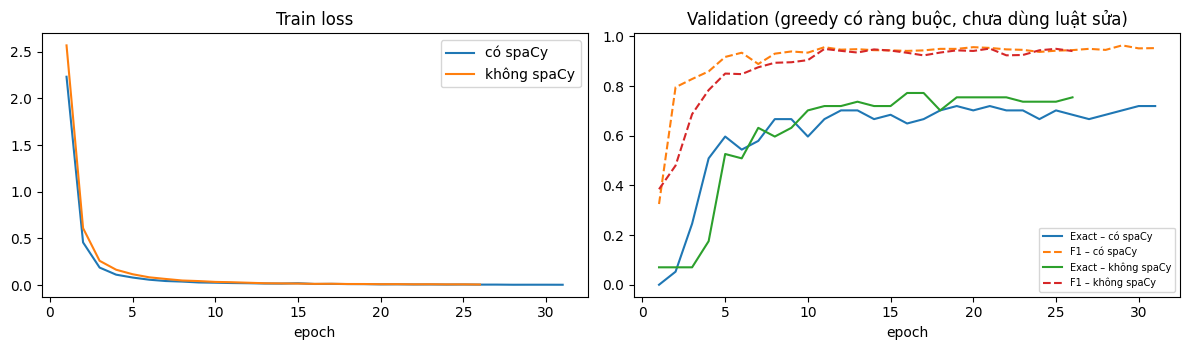

In [12]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name, lbl in (("spacy", "có spaCy"), ("plain", "không spaCy")):
    h = pd.DataFrame(histories[name])
    if len(h) and "val_exact" in h:
        ax[0].plot(h.epoch, h.train_loss, label=lbl)
        ax[1].plot(h.epoch, h.val_exact, label=f"Exact – {lbl}")
        ax[1].plot(h.epoch, h.val_lab_f1, "--", label=f"F1 – {lbl}")
ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation (greedy có ràng buộc, chưa dùng luật sửa)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 8.1. Chọn luật sửa lỗi & trọng số xếp hạng trên validation
1. Kiểm định chéo 5-fold từng luật trên cây chuẩn train → chỉ giữ luật an toàn (giữ nguyên ≥ `rule_audit_min` cây đúng).
2. Với mỗi tổ hợp luật an toàn × lưới trọng số (α prior, β nhãn lạ, μ MBR) × ngưỡng τ dùng template: chọn tổ hợp có **EM + F1** cao nhất trên val (hoà → nhiều luật an toàn hơn, trọng số nhỏ hơn, τ = −∞).
3. Tầng luật v3 cũng được chọn `alpha` trên val như trước, để làm dòng tham chiếu.

In [13]:
# Chọn tham số tầng luật bằng VALIDATION – tuyệt đối không dùng test.
assert models_phase == 1, "Mô hình hiện tại đã học cả val (pha 2) → chạy lại mục 8 trước khi chọn tham số trên val."

audit = audit_rules(train_groups)
SAFE_RULES = [r for r, v in audit.items() if v >= CFG["rule_audit_min"]]
print("Kiểm định chéo 5-fold (tỉ lệ cây chuẩn được giữ nguyên):", {r: f"{v*100:.1f}%" for r, v in audit.items()})
print("→ luật an toàn:", SAFE_RULES)

def nb_lists(free, cons, i):
    """Các danh sách n-best của câu thứ i (một mô hình): có ràng buộc (nếu có) trước, rồi tự do."""
    return ([cons[i]] if cons is not None else []) + [free[i]]

SYSTEMS = {   # hệ thống dùng luật v4: (các mô hình góp n-best, dùng spaCy?)
    "spacy": (("spacy",), True),
    "plain": (("plain",), False),
    "ensemble": (("spacy", "plain"), True),      # kết hợp n-best của cả 2 mô hình (dòng bổ sung, ngoài bảng 2×2)
}

val_nb = {}
for name, key in (("spacy", "src_spacy"), ("plain", "src_plain")):
    srcs = [g[key] for g in val_groups]
    free = nbest_generate(models[name], srcs)
    cons = nbest_generate(models[name], srcs, [g["sentence"] for g in val_groups], inv_train) if CFG["constrained"] else None
    val_nb[name] = (free, cons)

W_GRID = [(1.0, a, b, m) for a in (0.0, 0.05, 0.1, 0.2, 0.5, 1.0) for b in (0.0, 0.25, 0.5, 1.0) for m in (0.0, 1.0, 2.0, 5.0)]
TAU_GRID = [-math.inf, -1.0, -0.5, -0.3, -0.2, -0.1, -0.05]      # −∞ = không bao giờ thay bằng template

def tune_v4(model_names, use_spacy):
    sources = lambda i: [nb_lists(*val_nb[n], i) for n in model_names]
    usable = [r for r in SAFE_RULES if use_spacy or not POST_RULES[r][1]]
    best = None
    for k in range(len(usable) + 1):
        for rules in itertools.combinations(usable, k):
            per = []          # mỗi câu: (đặc trưng | None, thống kê từng ứng viên, độ tự tin, thống kê cây template | None)
            for i, g in enumerate(val_groups):
                doc = g["doc"] if use_spacy else None
                tags = leaf_tags(doc, g["sentence"]) if use_spacy else None
                pool, _ = build_pool(sources(i), g["sentence"], tags, res_train, rules)
                if pool:
                    trees, F = pool_features(pool, tags, res_train)
                    tmpl = template_tree(g["sentence"], doc, res_train, tags, rules) if use_spacy else None
                    per.append((F, [tree_stats(g["golds"], t) for t in trees], F[:, 0].max(),
                                tree_stats(g["golds"], tmpl) if tmpl is not None else None))
                else:
                    t, _ = decode_v4(sources(i), g["sentence"], doc, res_train, dict(DEFAULT_PARAMS, rules=rules), use_spacy)
                    per.append((None, [tree_stats(g["golds"], t)], None, None))
            for w in W_GRID:
                picks = [st[0] if F is None else st[int(np.argmax(F @ np.asarray(w)))] for F, st, _, _ in per]
                for ti, tau in enumerate(TAU_GRID if use_spacy else TAU_GRID[:1]):
                    rows = [tm if (tm is not None and conf < tau) else pk for pk, (_, _, conf, tm) in zip(picks, per)]
                    m = metrics_from_stats(rows)
                    key = (round(m["Exact Match"] + m["F1 (Labeled)"], 9), len(rules), -sum(w[1:]), -ti)
                    if best is None or key > best[0]:
                        best = (key, dict(rules=rules, w=w, tau=tau), m)
    return best[1], best[2]

PARAMS, val_rows = {}, {}
golds_val = [g["golds"] for g in val_groups]
for name, (mnames, use_sp) in SYSTEMS.items():
    PARAMS[name], val_rows[f"{name}: luật v4"] = tune_v4(mnames, use_sp)
    print(f"[{name}] luật = {list(PARAMS[name]['rules'])} | w (logp, α prior, β nhãn lạ, μ MBR) = {PARAMS[name]['w']}"
          f" | tau (ngưỡng dùng template) = {PARAMS[name]['tau']}")
for name in ("spacy", "plain"):
    val_rows[f"{name}: không luật (top-1)"] = eval_trees(golds_val, [predict_raw(t)[0] for t, _ in val_nb[name][0]])[0]

# Tầng luật v3 (tham chiếu): chọn alpha như bản cũ
ALPHA_GRID = [0.0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
alpha_v3 = {}
for name in ("spacy", "plain"):
    sp = name == "spacy"
    rows = []
    for a in ALPHA_GRID:
        preds = [predict_with_rules_v3(t, s, g["sentence"], g["doc"] if sp else None, res_train.prior,
                                       res_train.bank if sp else None, a)[0]
                 for (t, s), g in zip(val_nb[name][0], val_groups)]
        m, _ = eval_trees(golds_val, preds)
        rows.append((m["Exact Match"], m["F1 (Labeled)"], -a, a, m))
    best_ = max(rows, key=lambda r: r[:3])
    alpha_v3[name] = best_[3]
    val_rows[f"{name}: luật v3"] = best_[4]
print("alpha (luật v3):", alpha_v3)

show_val = (pd.DataFrame(val_rows).T * 100).round(2)
print(f"\nVALIDATION ({len(val_groups)} câu, mô hình pha 1) – đơn vị %. Lưu ý: tham số luật được chọn trên chính tập này nên số liệu hơi lạc quan.")
display(show_val[["Exact Match", "P (Labeled)", "R (Labeled)", "F1 (Labeled)", "Tag Acc", "Coverage (có cây)"]])
json.dump({"PARAMS": {k: dict(v, rules=list(v["rules"])) for k, v in PARAMS.items()},
           "alpha_v3": alpha_v3, "audit": audit},
          open(os.path.join(CFG["out_dir"], "rule_params.json"), "w"), indent=2, ensure_ascii=False)

Kiểm định chéo 5-fold (tỉ lệ cây chuẩn được giữ nguyên): {'tense': '99.7%', 'tense_add': '99.3%', 'subcat': '99.0%', 'lexicon': '99.3%', 'tagmap': '100.0%'}
→ luật an toàn: ['tense', 'tense_add', 'subcat', 'lexicon', 'tagmap']
[spacy] luật = ['tense', 'tense_add', 'subcat', 'lexicon', 'tagmap'] | w (logp, α prior, β nhãn lạ, μ MBR) = (1.0, 1.0, 0.25, 5.0) | tau (ngưỡng dùng template) = -inf
[plain] luật = ['lexicon'] | w (logp, α prior, β nhãn lạ, μ MBR) = (1.0, 0.05, 0.0, 0.0) | tau (ngưỡng dùng template) = -inf
[ensemble] luật = ['tense', 'lexicon', 'tagmap'] | w (logp, α prior, β nhãn lạ, μ MBR) = (1.0, 0.2, 1.0, 5.0) | tau (ngưỡng dùng template) = -inf
alpha (luật v3): {'spacy': 0.02, 'plain': 0.05}

VALIDATION (57 câu, mô hình pha 1) – đơn vị %. Lưu ý: tham số luật được chọn trên chính tập này nên số liệu hơi lạc quan.


,Exact Match,P (Labeled),R (Labeled),F1 (Labeled),Tag Acc,Coverage (có cây)
spacy: luật v4,75.44,97.94,96.36,97.14,96.30,100.00
plain: luật v4,78.95,96.72,95.55,96.13,95.62,100.00
ensemble: luật v4,78.95,98.15,96.76,97.45,97.31,100.00
spacy: không luật (top-1),57.89,94.55,77.33,85.08,79.12,85.96
plain: không luật (top-1),43.86,83.72,58.30,68.74,60.94,73.68
spacy: luật v3,68.42,96.43,92.91,94.64,93.94,98.25
plain: luật v3,75.44,97.14,89.47,93.15,89.56,94.74


## 9. Huấn luyện pha 2: train + val
Huấn luyện lại cả 2 mô hình **từ đầu** trên train + val (kèm câu tăng cường), đúng bằng số epoch tốt nhất của pha 1 và cùng lịch learning rate. Pha này không nhìn val. Tài nguyên luật cho test cũng học lại từ train + val. Tắt bằng `CFG["final_train_on_trainval"]=False`.

In [14]:
if CFG["final_train_on_trainval"]:
    trainval_ex, n_aug_tv = make_train_examples(by["train"] + by["val"])
    print(f"train+val gốc: {len(by['train']) + len(by['val'])} | câu tăng cường: {n_aug_tv} | tổng {len(trainval_ex)} mẫu")
    for name, use_sp in (("spacy", True), ("plain", False)):
        E = best_epochs.get(name) or CFG["epochs"]
        del models[name]; free_memory()
        models[name], histories[f"{name}_trainval"], _ = train_variant(f"{name}_trainval", use_sp, trainval_ex, fixed_epochs=E)
    models_phase = 2
    fit_groups = train_groups + val_groups
else:
    fit_groups = train_groups

# Tài nguyên luật dùng cho TEST: học từ đúng phần dữ liệu mô hình đã thấy (không bao giờ có test)
res_test = RuleResources(fit_groups)
inv_test = ConstraintInventory(res_test, tok)
print(f"Tài nguyên luật cho test học từ {len(fit_groups)} câu | kho nhãn ràng buộc: {len(res_test.labels)}")

train+val gốc: 359 | câu tăng cường: 335 | tổng 694 mẫu


Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


[spacy_trainval] 783M tham số | spaCy hints=True | 694 mẫu | optimizer=adamw lr=0.0001 | bf16=True
[spacy_trainval] [   25s] {'epoch': 1, 'train_loss': 2.0755}
[spacy_trainval] [   49s] {'epoch': 2, 'train_loss': 0.3725}
[spacy_trainval] [   74s] {'epoch': 3, 'train_loss': 0.1626}
[spacy_trainval] [   99s] {'epoch': 4, 'train_loss': 0.1006}
[spacy_trainval] [  124s] {'epoch': 5, 'train_loss': 0.0649}
[spacy_trainval] [  149s] {'epoch': 6, 'train_loss': 0.0485}
[spacy_trainval] [  173s] {'epoch': 7, 'train_loss': 0.0404}
[spacy_trainval] [  198s] {'epoch': 8, 'train_loss': 0.0358}
[spacy_trainval] [  223s] {'epoch': 9, 'train_loss': 0.0314}
[spacy_trainval] [  247s] {'epoch': 10, 'train_loss': 0.0231}
[spacy_trainval] [  272s] {'epoch': 11, 'train_loss': 0.0177}
[spacy_trainval] [  297s] {'epoch': 12, 'train_loss': 0.0166}
[spacy_trainval] [  322s] {'epoch': 13, 'train_loss': 0.0154}
[spacy_trainval] [  347s] {'epoch': 14, 'train_loss': 0.0144}
[spacy_trainval] [  372s] {'epoch': 15, 't

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


[plain_trainval] 783M tham số | spaCy hints=False | 694 mẫu | optimizer=adamw lr=0.0001 | bf16=True
[plain_trainval] [   25s] {'epoch': 1, 'train_loss': 2.4207}
[plain_trainval] [   50s] {'epoch': 2, 'train_loss': 0.5268}
[plain_trainval] [   74s] {'epoch': 3, 'train_loss': 0.2264}
[plain_trainval] [   99s] {'epoch': 4, 'train_loss': 0.1455}
[plain_trainval] [  124s] {'epoch': 5, 'train_loss': 0.1}
[plain_trainval] [  148s] {'epoch': 6, 'train_loss': 0.0779}
[plain_trainval] [  173s] {'epoch': 7, 'train_loss': 0.0565}
[plain_trainval] [  197s] {'epoch': 8, 'train_loss': 0.0432}
[plain_trainval] [  222s] {'epoch': 9, 'train_loss': 0.0373}
[plain_trainval] [  247s] {'epoch': 10, 'train_loss': 0.0312}
[plain_trainval] [  271s] {'epoch': 11, 'train_loss': 0.0249}
[plain_trainval] [  296s] {'epoch': 12, 'train_loss': 0.0218}
[plain_trainval] [  320s] {'epoch': 13, 'train_loss': 0.0192}
[plain_trainval] [  345s] {'epoch': 14, 'train_loss': 0.0173}
[plain_trainval] [  370s] {'epoch': 15, 'tra

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[plain_trainval] → syntax_model_v4/ckpt_plain_trainval
Tài nguyên luật cho test học từ 351 câu | kho nhãn ràng buộc: 93


## 10. TEST – Mô hình đầy đủ · Bỏ spaCy · Bỏ luật · Gốc

In [15]:
# ═══════════════════════════════════════════════════════════════════════════════
#  TEST: so sánh 4 mô hình (thiết kế 2×2)
#
#                         │  CÓ luật (v4)         │  KHÔNG luật
#   ──────────────────────┼───────────────────────┼─────────────────────────
#   CÓ spaCy (model A)    │ 1. Mô hình đầy đủ     │ 3. Mô hình bỏ luật
#   KHÔNG spaCy (model B) │ 2. Mô hình bỏ spaCy   │ 4. Mô hình gốc (T5 thuần)
#
#  Cùng tập test, cùng beam search; chỉ khác phần bị bỏ. Tập test chỉ dùng ở cell này.
#  "Luật" gồm cả giải mã có ràng buộc; "không luật" = top-1 của beam search tự do.
# ═══════════════════════════════════════════════════════════════════════════════
test_sent  = [g["sentence"] for g in test_groups]
golds_test = [g["golds"] for g in test_groups]

nb_free, nb_cons = {}, {}
for name, key in (("spacy", "src_spacy"), ("plain", "src_plain")):
    srcs = [g[key] for g in test_groups]
    nb_free[name] = nbest_generate(models[name], srcs)
    nb_cons[name] = nbest_generate(models[name], srcs, test_sent, inv_test) if CFG["constrained"] else None

VARIANTS = [   # (tên hiển thị, mô hình, dùng luật?)
    ("1. Đầy đủ (spaCy + luật)",      "spacy", True),
    ("2. Bỏ spaCy",                   "plain", True),
    ("3. Bỏ luật",                    "spacy", False),
    ("4. Gốc (T5 thuần)",             "plain", False),
]

def run_variant(model_name, use_rules):
    preds, stats = [], []
    sp = model_name == "spacy"
    for i, g in enumerate(test_groups):
        if use_rules:
            # "Bỏ spaCy" bỏ HOÀN TOÀN spaCy: không gợi ý nguồn (model B), không luật cần tag, không template fallback
            t, st = decode_v4([nb_lists(nb_free[model_name], nb_cons[model_name], i)], g["sentence"],
                              g["doc"] if sp else None, res_test, PARAMS[model_name], use_spacy=sp)
        else:
            t, st = predict_raw(nb_free[model_name][i][0])
        preds.append(t); stats.append(st)
    return preds, stats

results, preds_by, stats_by, exact_vec = {}, {}, {}, {}
for label, mname, use_rules in VARIANTS:
    preds_by[label], stats_by[label] = run_variant(mname, use_rules)
    results[label], exact_vec[label] = eval_trees(golds_test, preds_by[label], test_sent, res_test.prior)

# Dòng bổ sung (ngoài bảng 2×2): kết hợp n-best của CẢ 2 mô hình + spaCy + luật v4 (tham số chọn trên val)
lbl = "5. Kết hợp A+B (spaCy + luật)"
out = [decode_v4([nb_lists(nb_free[n], nb_cons[n], i) for n in SYSTEMS["ensemble"][0]], g["sentence"], g["doc"],
                 res_test, PARAMS["ensemble"], use_spacy=True) for i, g in enumerate(test_groups)]
preds_by[lbl], stats_by[lbl] = [o[0] for o in out], [o[1] for o in out]
results[lbl], exact_vec[lbl] = eval_trees(golds_test, preds_by[lbl], test_sent, res_test.prior)

if CFG["include_legacy_rules"]:  # dòng tham chiếu: CÙNG mô hình đầy đủ nhưng dùng tầng luật v3 cũ
    lbl = "1*. (tham chiếu) Đầy đủ + luật v3 cũ"
    out = [predict_with_rules_v3(t, s, g["sentence"], g["doc"], res_test.prior, res_test.bank, alpha_v3["spacy"])
           for (t, s), g in zip(nb_free["spacy"], test_groups)]
    preds_by[lbl], stats_by[lbl] = [o[0] for o in out], [o[1] for o in out]
    results[lbl], exact_vec[lbl] = eval_trees(golds_test, preds_by[lbl], test_sent, res_test.prior)

if CFG["include_zero_shot"]:     # dòng tham chiếu: T5-large CHƯA fine-tune (không spaCy, không luật)
    _zs = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_name"]).to(device).eval()
    _nb = nbest_generate(_zs, [g["src_plain"] for g in test_groups])
    lbl = "0. (tham chiếu) T5-large chưa fine-tune"
    preds_by[lbl] = [text_to_tree(t[0]) for t, _ in _nb]
    stats_by[lbl] = ["raw" if p is not None else "unparsable" for p in preds_by[lbl]]
    results[lbl], exact_vec[lbl] = eval_trees(golds_test, preds_by[lbl], test_sent, res_test.prior)
    del _zs
    free_memory()

table = pd.DataFrame(results).T
ci = {k: bootstrap_ci(v) for k, v in exact_vec.items()}
table["Exact 95% CI"] = [f"[{ci[k][0]*100:.1f}, {ci[k][1]*100:.1f}]" for k in table.index]
pct_cols = [c for c in table.columns if c != "Exact 95% CI"]
show = table.copy(); show[pct_cols] = (show[pct_cols] * 100).round(2)
print(f"KẾT QUẢ TRÊN TẬP TEST ({len(test_groups)} câu) – đơn vị %")
display(show.sort_index())
table.to_csv(os.path.join(CFG["out_dir"], "test_ablation_4_models.csv"), encoding="utf-8-sig")

# Chênh lệch có ý nghĩa không? (bootstrap ghép cặp trên Exact Match)
def paired_diff(a, b, n_boot=2000, seed=1):
    rng = np.random.default_rng(seed); d = np.asarray(exact_vec[a]) - np.asarray(exact_vec[b])
    bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)]
    return d.mean() * 100, np.percentile(bs, 2.5) * 100, np.percentile(bs, 97.5) * 100
full = VARIANTS[0][0]
for label in [l for l in preds_by if l != full and not l.startswith("0.")]:
    m_, lo, hi = paired_diff(full, label)
    print(f"Δ Exact (Đầy đủ − {label}): {m_:+.1f} điểm %  | 95% CI [{lo:+.1f}, {hi:+.1f}]")

# Mô hình đầy đủ: cây đến từ đâu và đúng bao nhiêu?
print("\nNguồn cây của MÔ HÌNH ĐẦY ĐỦ:")
src_df = pd.DataFrame(dict(status=stats_by[full], exact=exact_vec[full]))
print(src_df.groupby("status").agg(số_câu=("exact", "size"), exact=("exact", "mean")).round(3).to_string())
print("\nSố câu KHÔNG có cây:", {l: sum(p is None for p in preds_by[l]) for l in preds_by})

# Theo thể loại câu
cats = sorted({g["category"] for g in test_groups})
cat_rows = []
for c in cats:
    ix = [i for i, g in enumerate(test_groups) if g["category"] == c]
    row = {"category": c, "n": len(ix)}
    for l in preds_by:
        row[l.split(".")[0] + ". Exact"] = round(float(np.mean([exact_vec[l][i] for i in ix])) * 100, 1)
    cat_rows.append(row)
print("\nExact Match (%) theo thể loại:")
print(pd.DataFrame(cat_rows).to_string(index=False))

# Lưu dự đoán chi tiết + câu sai của mô hình đầy đủ
rows = []
for i, g in enumerate(test_groups):
    r = dict(sentence=g["sentence"], category=g["category"], gold=" || ".join(to_str(x) for x in g["golds"]))
    for l in preds_by:
        k = l.split(".")[0]
        r[f"pred_{k}"] = to_str(preds_by[l][i]) if preds_by[l][i] else ""
        r[f"status_{k}"] = stats_by[l][i]
        r[f"exact_{k}"] = bool(exact_vec[l][i])
    r["raw_top1_spacy"] = nb_free["spacy"][i][0][0]
    rows.append(r)
pd.DataFrame(rows).to_csv(os.path.join(CFG["out_dir"], "test_predictions_all_variants.csv"), index=False, encoding="utf-8-sig")
json.dump({"results": results, "params": {k: dict(v, rules=list(v["rules"])) for k, v in PARAMS.items()},
           "alpha_v3": alpha_v3, "best_epochs": best_epochs, "cfg": CFG},
          open(os.path.join(CFG["out_dir"], "test_metrics.json"), "w"), indent=2, ensure_ascii=False)

print("\nCÁC CÂU MÔ HÌNH ĐẦY ĐỦ CHƯA ĐÚNG (tối đa 12):")
shown = 0
for i, g in enumerate(test_groups):
    if exact_vec[full][i] < 1 and shown < 12:
        shown += 1
        print(f"- [{stats_by[full][i]}] {g['sentence']}\n    gold: {to_str(g['golds'][0])}\n    pred: {to_str(preds_by[full][i]) if preds_by[full][i] else 'KHÔNG CÓ CÂY'}")

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


KẾT QUẢ TRÊN TẬP TEST (69 câu) – đơn vị %


,Exact Match,Exact (bỏ qua từ),P (Labeled),R (Labeled),F1 (Labeled),P (Unlabeled),R (Unlabeled),F1 (Unlabeled),Tag Acc,Coverage (có cây),Well-formed,Exact 95% CI
0. (tham chiếu) T5-large chưa fine-tune,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"[0.0, 0.0]"
1*. (tham chiếu) Đầy đủ + luật v3 cũ,66.67,66.67,96.09,92.93,94.48,97.79,94.57,96.15,93.97,100.00,100.00,"[56.5, 76.8]"
1. Đầy đủ (spaCy + luật),79.71,79.71,96.33,94.90,95.61,97.83,96.38,97.10,95.07,100.00,100.00,"[71.0, 88.4]"
2. Bỏ spaCy,73.91,73.91,96.03,95.56,95.80,98.84,98.36,98.60,92.88,100.00,100.00,"[63.8, 84.1]"
3. Bỏ luật,49.28,49.28,94.52,65.30,77.24,96.90,66.94,79.18,66.03,72.46,68.12,"[37.7, 60.9]"
4. Gốc (T5 thuần),33.33,33.33,90.45,46.71,61.61,93.95,48.52,63.99,46.30,55.07,49.28,"[23.2, 44.9]"
5. Kết hợp A+B (spaCy + luật),73.91,73.91,97.85,97.20,97.52,99.17,98.52,98.84,95.62,100.00,100.00,"[63.8, 84.1]"


Δ Exact (Đầy đủ − 2. Bỏ spaCy): +5.8 điểm %  | 95% CI [+0.0, +13.0]
Δ Exact (Đầy đủ − 3. Bỏ luật): +30.4 điểm %  | 95% CI [+20.3, +42.0]
Δ Exact (Đầy đủ − 4. Gốc (T5 thuần)): +46.4 điểm %  | 95% CI [+34.8, +58.0]
Δ Exact (Đầy đủ − 5. Kết hợp A+B (spaCy + luật)): +5.8 điểm %  | 95% CI [+0.0, +13.0]
Δ Exact (Đầy đủ − 1*. (tham chiếu) Đầy đủ + luật v3 cũ): +13.0 điểm %  | 95% CI [+5.8, +21.7]

Nguồn cây của MÔ HÌNH ĐẦY ĐỦ:
        số_câu  exact
status               
ok          69  0.797

Số câu KHÔNG có cây: {'1. Đầy đủ (spaCy + luật)': 0, '2. Bỏ spaCy': 0, '3. Bỏ luật': 19, '4. Gốc (T5 thuần)': 31, '5. Kết hợp A+B (spaCy + luật)': 0, '1*. (tham chiếu) Đầy đủ + luật v3 cũ': 0, '0. (tham chiếu) T5-large chưa fine-tune': 69}

Exact Match (%) theo thể loại:
                     category  n  1. Exact  2. Exact  3. Exact  4. Exact  5. Exact  1*. Exact  0. Exact
      adjective_adverb_phrase  4     100.0     100.0      75.0      25.0     100.0      100.0       0.0
         adverbial_clause_ch8

In [16]:
# Bảng Exact Match (%) theo thể loại câu cho mọi phiên bản → Excel (tự tải về nếu chạy trên Colab)
if 'test_groups' not in globals() or 'exact_vec' not in globals() or 'preds_by' not in globals():
    raise NameError("Hãy chạy cell TEST (mục 10) phía trên trước khi chạy cell này.")

cats = sorted({g["category"] for g in test_groups})
cat_rows = []
for c in cats:
    ix = [i for i, g in enumerate(test_groups) if g["category"] == c]
    row = {"Thể loại câu (Category)": c, "Số mẫu (n)": len(ix)}
    for l in preds_by:
        row[l.split(".")[0] + ". Exact (%)"] = round(float(np.mean([exact_vec[l][i] for i in ix])) * 100, 2)
    cat_rows.append(row)

df_cat_results = pd.DataFrame(cat_rows)
display(df_cat_results)

output_file = os.path.join(CFG["out_dir"], "chinh_xac_theo_loai_cau.xlsx")
with pd.ExcelWriter(output_file) as xw:
    df_cat_results.to_excel(xw, sheet_name="theo_the_loai", index=False)
    show.sort_index().to_excel(xw, sheet_name="tong_hop_test")
print(f"\nĐã lưu báo cáo tại: {output_file}")

try:
    from google.colab import files
    files.download(output_file)
    print("Đang tải file xuống...")
except Exception:
    print("Không tự tải xuống được (không phải Colab). File nằm tại:", output_file)

,Thể loại câu (Category),Số mẫu (n),1. Exact (%),2. Exact (%),3. Exact (%),4. Exact (%),5. Exact (%),1*. Exact (%),0. Exact (%)
0,adjective_adverb_phrase,4,100.00,100.00,75.00,25.00,100.00,100.00,0.0
1,adverbial_clause_ch8,2,100.00,100.00,50.00,50.00,50.00,50.00,0.0
2,auxiliary_sequences_ch6,2,50.00,0.00,50.00,0.00,0.00,50.00,0.0
3,complement_clause_ch8,2,0.00,0.00,0.00,0.00,0.00,0.00,0.0
4,complex_transitive_ch4,2,100.00,100.00,50.00,50.00,100.00,100.00,0.0
5,coordination,4,75.00,75.00,75.00,75.00,75.00,75.00,0.0
6,coordination_ambiguity_ch3_11,2,50.00,0.00,0.00,0.00,50.00,0.00,0.0
7,copular,4,100.00,100.00,100.00,75.00,100.00,100.00,0.0
8,ditransitive,4,100.00,100.00,50.00,25.00,75.00,50.00,0.0
9,ellipsis_ch5,2,0.00,50.00,0.00,0.00,50.00,0.00,0.0



Đã lưu báo cáo tại: syntax_model_v4/chinh_xac_theo_loai_cau.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Đang tải file xuống...


## 11. Pipeline suy luận hoàn chỉnh (mô hình đầy đủ)

In [17]:
from spellchecker import SpellChecker
spell = SpellChecker()

# Ứng dụng dùng hệ thống tốt nhất trên VALIDATION trong hai lựa chọn: mô hình đầy đủ (A + spaCy + luật v4)
# hoặc kết hợp A+B. Tài nguyên luật học từ train + val (sau khi đã đánh giá xong).
res_app = res_test if CFG["final_train_on_trainval"] else RuleResources(train_groups + val_groups)
inv_app = ConstraintInventory(res_app, tok)

def preprocess(text, autocorrect=False):
    t = unicodedata.normalize("NFKC", text).replace("’", "'").replace("“", '"').replace("”", '"')
    t = re.sub(r"\s+", " ", t).strip()
    sents = [s.text.strip() for s in nlp(t).sents if s.text.strip()][:5]
    out, notes = [], []
    for s in sents:
        words = [w for w in re.findall(r"[A-Za-z']+", s) if w.islower()]
        fixes = {w: spell.correction(w) for w in spell.unknown(words)}
        fixes = {w: c for w, c in fixes.items() if c and c != w}
        if fixes:
            notes.append("Có thể sai chính tả: " + ", ".join(f"**{w}** → *{c}*" for w, c in fixes.items()))
            if autocorrect:
                s = re.sub(r"\b(" + "|".join(map(re.escape, fixes)) + r")\b", lambda m: fixes[m.group(1)], s)
        if s[-1].isalnum():
            s += "."
        out.append(s)
    return out, notes

_vk = lambda n: (round(val_rows[f"{n}: luật v4"]["Exact Match"] + val_rows[f"{n}: luật v4"]["F1 (Labeled)"], 9), n == "spacy")
APP_SYSTEM = max(("spacy", "ensemble"), key=_vk)
print("Ứng dụng dùng hệ thống:", APP_SYSTEM)

def analyse_sentence(sentence):
    doc = nlp(sentence)
    sources = []
    for n in SYSTEMS[APP_SYSTEM][0]:
        src = make_src(sentence, doc, n == "spacy")
        lists = [nbest_generate(models[n], [src], [sentence], inv_app)[0]] if CFG["constrained"] else []
        sources.append(lists + [nbest_generate(models[n], [src])[0]])
    return decode_v4(sources, sentence, doc, res_app, PARAMS[APP_SYSTEM], use_spacy=True)

def analyse(text, autocorrect=False):
    sents, notes = preprocess(text, autocorrect)
    return [(s, *analyse_sentence(s)) for s in sents], notes

# Kiểm tra nhanh: các câu đơn giản PHẢI ra cây
for s in ["The dog barked.", "Mary gave John a book.", "The teacher praised the student.", "She is happy."]:
    tr, st = analyse_sentence(s)
    print(f"[{st:12s}] {s} → {to_str(tr) if tr else 'KHÔNG CÓ CÂY'}")

Ứng dụng dùng hệ thống: ensemble
[ok          ] The dog barked. → (S (NP (DET (ART The)) (NOM (N dog))) (VP (V[intrans][past] barked)))
[ok          ] Mary gave John a book. → (S (NP (name Mary)) (VP (V[ditrans][past] gave) (NP (name John)) (NP (DET (ART a)) (NOM (N book)))))
[ok          ] The teacher praised the student. → (S (NP (DET (ART The)) (NOM (N teacher))) (VP (V[trans][past] praised) (NP (DET (ART the)) (NOM (N student)))))
[ok          ] She is happy. → (S (NP (pronoun She)) (VP (V[intens][pres] is) (AP (A happy))))


## 12. Giao diện Gradio

In [18]:
import gradio as gr, html

EXAMPLES = ["The scientist examined the sample.", "Mary gave John a book.", "The dog barked.",
            "The teacher praised the student.", "She saw the man with the telescope."]
STATUS_VI = {"ok": "", "realigned": "⚠️ Đã căn lại từ trong cây theo đúng câu nhập.",
             "repaired": "⚠️ Đã tự sửa ngoặc của cây sinh ra.",
             "fallback": "⚠️ Mô hình không sinh được cây hợp lệ – đây là cây dựng từ câu mẫu tương tự, cần kiểm tra.",
             "fallback_low": "⚠️ Cây dựng từ câu mẫu chỉ hơi giống câu nhập – độ tin cậy thấp, cần kiểm tra thủ công.",
             "invalid": "❌ Không dựng được cây hợp lệ cho câu này."}

def ui(text, autocorrect):
    if not text.strip():
        return "", "<p>Hãy nhập một câu tiếng Anh.</p>", ""
    results, notes = analyse(text, autocorrect)
    cards, infos = [], []
    for s, tree, status in results:
        warn = STATUS_VI.get(status, "")
        if tree is None:
            cards.append(f"<h4>{html.escape(s)}</h4><p>{warn}</p>"); continue
        cards.append(f"<h4>{html.escape(s)}</h4><p>{warn}</p>"
                     f"<div style='overflow-x:auto;background:white;border-radius:8px;padding:8px'>{tree_to_svg(tree)}</div>"
                     f"<pre style='white-space:pre-wrap'>{html.escape(to_str(tree))}</pre>")
        gi = grammar_info(tree)
        infos.append(f"### {s}\n" + "\n".join(f"- **{k}:** " + "; ".join(v) for k, v in gi.items()))
    return "\n\n".join(notes), "<hr>".join(cards), "\n\n".join(infos)

with gr.Blocks(title="English Syntax Explorer") as demo:
    gr.Markdown("# English Syntax Explorer\nPhân tích cấu trúc cú pháp tiếng Anh theo khung Burton-Roberts (*Analysing Sentences*).")
    with gr.Row():
        inp = gr.Textbox(label="Câu tiếng Anh", lines=2, scale=4)
        chk = gr.Checkbox(label="Tự động sửa chính tả", value=False, scale=1)
    btn = gr.Button("Phân tích", variant="primary")
    note_out = gr.Markdown()
    tree_out = gr.HTML(label="Cây cú pháp")
    info_out = gr.Markdown()
    gr.Examples(EXAMPLES, inputs=inp)
    btn.click(ui, [inp, chk], [note_out, tree_out, info_out])
    inp.submit(ui, [inp, chk], [note_out, tree_out, info_out])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://38d10e9957d439d735.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
